# Exercise 1 &mdash; Deep learning for a conventional 6G text link with multi-user resource allocation

**Author:** Tathagata Banerjee, IIT Dharwad &nbsp;|&nbsp; **Reference:** *Semantic Communications in 6G* notebook (BART + Huffman + convolutional code + QAM + Rayleigh + ZF + Viterbi) &nbsp;|&nbsp; **Problem statement:** Lab 10, Exercise 1

This notebook implements **everything** asked in Exercise 1 and reproduces every figure of the paper and the slides.
It is the *conventional* (bit-level) baseline; Exercise 2 (semantic communication) will reuse the same cell, the same channel drops and the same look-up table.

| Part | What is implemented | Where |
|---|---|---|
| **Task 1** | char-Huffman &rarr; conv. encoder (K=7, 133/171, punctured 2/3, 3/4) &rarr; Gray QPSK/16/64-QAM &rarr; AWGN / Rayleigh block fading &rarr; ZF &rarr; max-log LLR &rarr; soft Viterbi &rarr; text. (a) BER validation against exact theory, (b) coded BER/BLER for 6 MCS, (c) BLEU / word accuracy / sentence similarity and the cliff effect, (d) BLER and similarity look-up tables + AMC rule | section 3 |
| **Task 2** | (7,4) and (2,4) autoencoders vs Hamming(7,4) hard/ML, uncoded BPSK and 16-QAM, in AWGN and Rayleigh with CSI | section 4 |
| **Task 3** | U=8, N=16 RBs: 4 benchmarks (round-robin, strongest+water-filling, exact MILP, MILP+KKT water-filling), unsupervised L2O DNN and DNN+KKT hybrid, five metrics, and the cross-layer metric *correct sentences per second* through the AMC rule | section 5 |

### How to run
* `RUN_MODE = "load"` (default) &mdash; uses the saved results/trained networks shipped in `results/` and `data/`; the whole notebook executes in about a minute and regenerates all figures.
* `RUN_MODE = "quick"` &mdash; re-runs every experiment at reduced size (about 10 min) in a separate folder `quick_run/` (does not touch the saved results).
* `RUN_MODE = "full"` &mdash; re-runs everything at the full size reported in the paper (about 45 min on 2 CPU cores).

Set it with the environment variable `EX1_MODE` before starting Jupyter, or edit the first code cell.

### How the code cells work
Every code cell that starts with `%%module name` holds the complete source of `code/name.py` (same file as in the repository, with all comments and docstrings). The magic compiles it as a module and registers it in `sys.modules`, so the modules import each other exactly as in the scripts (`from config import *`, `import link`, ...). The one-command alternative is `cd code && python run_all.py`.


## 0. Setup, run mode and the `%%module` magic

In [1]:
import os, sys, shutil, importlib, subprocess, types, time

# ----------------------------------------------------------------- run mode
RUN_MODE = os.environ.get("EX1_MODE", "load")          # "load" | "quick" | "full"
assert RUN_MODE in ("load", "quick", "full")

# project root = folder that contains code/, results/, data/, figures/ (parent of notebooks/)
PROJECT = os.path.abspath(os.environ.get("EX1_PROJECT", os.path.join(os.getcwd(), "..")))
if not os.path.isdir(os.path.join(PROJECT, "code")):    # e.g. notebook uploaded alone to Colab
    PROJECT = os.getcwd()
if RUN_MODE == "load" and not os.path.isdir(os.path.join(PROJECT, "results")):
    print("No saved results found -> switching to RUN_MODE='quick'")
    RUN_MODE = "quick"

if RUN_MODE == "quick":                                 # reduced sizes, separate output folder
    os.environ["EX1_QUICK"] = "1"
    ROOT_RUN = os.path.join(PROJECT, "quick_run")
    os.makedirs(os.path.join(ROOT_RUN, "data"), exist_ok=True)
    cache = os.path.join(PROJECT, "data", "sentences.json")  # reuse the corpus cache if present
    if os.path.exists(cache):
        shutil.copy(cache, os.path.join(ROOT_RUN, "data", "sentences.json"))
else:
    os.environ["EX1_QUICK"] = "0"
    ROOT_RUN = PROJECT
# multiprocessing of the Task-1 sweep only works with fork (Linux); use 1 worker elsewhere
os.environ.setdefault("EX1_WORKERS", "2" if sys.platform.startswith("linux") else "1")

# ----------------------------------------------------------------- dependencies
for pkg, mod in [("numpy", "numpy"), ("scipy", "scipy"), ("torch", "torch"),
                 ("matplotlib", "matplotlib"), ("gensim", "gensim")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

# ----------------------------------------------------------------- the %%module magic
from IPython.core.magic import register_cell_magic
MODULE_SOURCE = {}

@register_cell_magic
def module(line, cell):
    """%%module <name>: execute the cell as module <name> and register it in sys.modules."""
    name = line.split()[0]
    mod = types.ModuleType(name)
    mod.__file__ = os.path.join(ROOT_RUN, "code", name + ".py")   # config.py derives ROOT from this
    sys.modules[name] = mod
    MODULE_SOURCE[name] = cell
    exec(compile(cell, mod.__file__, "exec"), mod.__dict__)
    get_ipython().user_ns[name] = mod

def selftest(name):
    """Run the `if __name__ == "__main__":` self-test block of a module defined above."""
    ns = dict(sys.modules[name].__dict__); ns["__name__"] = "__main__"
    exec(compile(MODULE_SOURCE[name], name + ".py", "exec"), ns)

print(f"RUN_MODE = {RUN_MODE}   |   project = {PROJECT}   |   outputs under {ROOT_RUN}")

RUN_MODE = load   |   project = /home/claude/ex1   |   outputs under /home/claude/ex1


## 1. System parameters, corpus and source coding

**`config.py`** holds *every* number of Table&nbsp;1 of the problem statement (cell geometry, path loss, shadowing, noise, F, R<sub>min</sub>, MCS table, simulation sizes). Exercise&nbsp;2 imports the same file, so both exercises run on an identical cell.

**`corpus.py`** downloads the Brown corpus, detokenises it, keeps printable-ASCII sentences of 40&ndash;110 characters, removes duplicates, shuffles with a fixed seed and splits 20&nbsp;000 train / 2&nbsp;000 test sentences.

**`source_coding.py`** is the character-level Huffman code (add-one smoothed over the 95 printable characters plus an end-of-sentence symbol). Because Huffman is a variable-length code with no resynchronisation, one wrong bit corrupts the rest of the sentence &mdash; the root cause of the cliff effect studied in Task&nbsp;1(c).

In [2]:
%%module config
"""
config.py -- every tunable number of Exercise 1 lives here (single source of truth).

Why a config module?  Exercise 2 (semantic communication) must run on *the same
cell* and be compared with this system, so all system parameters (Table 1 of the
problem statement) are defined once and imported by every module.

Set the environment variable  EX1_QUICK=1  to run a drastically reduced version of
every experiment (a few minutes) -- useful as a smoke test.  The default (full)
setting reproduces the figures/numbers reported in the paper.
"""
import os
import numpy as np

QUICK = os.environ.get("EX1_QUICK", "0") == "1"

# --------------------------------------------------------------------------
# Directories
# --------------------------------------------------------------------------
ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
DATA_DIR = os.path.join(ROOT, "data")          # corpus + trained models + LUTs
FIG_DIR = os.path.join(ROOT, "figures")        # every PNG/PDF figure
RES_DIR = os.path.join(ROOT, "results")        # JSON/CSV numbers quoted in the paper
for _d in (DATA_DIR, FIG_DIR, RES_DIR):
    os.makedirs(_d, exist_ok=True)

SEED = 2026                                    # global reproducibility seed

# --------------------------------------------------------------------------
# Table 1 of the problem statement -- simulation parameters
# --------------------------------------------------------------------------
U = 8                       # number of single-antenna users
N = 16                      # number of OFDMA resource blocks (RBs)
B_RB = 180e3                # RB bandwidth [Hz]
CELL_RADIUS_M = 500.0       # cell radius [m]
MIN_DIST_M = 35.0           # minimum BS-user distance [m]
PMAX_DBM_DEFAULT = 30.0     # BS transmit power budget [dBm]
PMAX_DBM_SWEEP = np.arange(15.0, 40.1, 2.5)   # 15 ... 40 dBm
PL_A_DB = 128.1             # path loss  128.1 + 37.6 log10(d/1km)  [dB]
PL_B_DB = 37.6
SHADOW_STD_DB = 8.0         # log-normal shadowing standard deviation [dB]
NOISE_PSD_DBM_HZ = -174.0   # thermal noise PSD [dBm/Hz]
NOISE_FIGURE_DB = 9.0       # receiver noise figure F [dB]
R_MIN = 1e6                 # minimum user rate [bit/s]

N_TRAIN_SENT = 20000        # >= 20 000 training sentences (Table 1)
N_TEST_SENT = 2000          # >= 2 000 test sentences      (Table 1)

# --------------------------------------------------------------------------
# Task 1 -- link-level simulation
# --------------------------------------------------------------------------
# (name, bits per symbol m, code rate)
MCS_TABLE = [
    dict(name="QPSK 1/2",   mod="QPSK",   m=2, rate="1/2", r=1 / 2),
    dict(name="QPSK 3/4",   mod="QPSK",   m=2, rate="3/4", r=3 / 4),
    dict(name="16-QAM 1/2", mod="16QAM",  m=4, rate="1/2", r=1 / 2),
    dict(name="16-QAM 3/4", mod="16QAM",  m=4, rate="3/4", r=3 / 4),
    dict(name="64-QAM 2/3", mod="64QAM",  m=6, rate="2/3", r=2 / 3),
    dict(name="64-QAM 3/4", mod="64QAM",  m=6, rate="3/4", r=3 / 4),
]
for _mc in MCS_TABLE:                       # spectral efficiency [information bit / symbol]
    _mc["eta"] = _mc["m"] * _mc["r"]

BLER_TARGET = 0.10          # AMC rule: highest-rate MCS with BLER <= 10 %

if QUICK:
    LINK_NFRAMES = 300                       # sentences per (MCS, SNR) point
    SNR_GRID_AWGN = np.arange(0.0, 30.1, 2.0)
    SNR_GRID_RAYL = np.arange(0.0, 36.1, 3.0)
    BER_VALID_BITS = 200_000
else:
    LINK_NFRAMES = N_TEST_SENT              # all 2000 test sentences per point
    SNR_GRID_AWGN = np.arange(0.0, 30.01, 0.5)   # 0.5 dB grid -> fine LUT
    SNR_GRID_RAYL = np.arange(0.0, 36.01, 1.0)
    BER_VALID_BITS = 2_000_000

# --------------------------------------------------------------------------
# Task 2 -- autoencoder
# --------------------------------------------------------------------------
AE_EBN0_GRID = np.arange(-2.0, 10.01, 1.0)   # dB
AE_TRAIN_ITERS = 400 if QUICK else 12000
AE_BATCH = 2048
AE_EVAL_MSGS = 200_000 if QUICK else 2_000_000

# --------------------------------------------------------------------------
# Task 3 -- resource allocation
# --------------------------------------------------------------------------
RA_TEST_DROPS = 40 if QUICK else 300       # random channel realisations per Pmax
RA_TRAIN_ITERS = 500 if QUICK else 12000
RA_BATCH = 256


In [3]:
%%module corpus
"""
corpus.py -- English text corpus for the text-communication link.

Source: the Brown Corpus (Kucera & Francis, ~57k English sentences from 15 genres,
distributed with NLTK's `nltk_data`).  It is downloaded once from the public
nltk_data GitHub repository and cached under data/.

Pre-processing
--------------
* The corpus is POS-tagged ("word/tag").  We keep the word, drop the tag.
* Tokens are de-tokenised to normal running text (no space before , . ; : ? !,
  PTB-style quotes `` '' become ").
* Only printable 7-bit ASCII is kept (95 symbols) so the character-level Huffman
  alphabet is small and well defined.
* Sentences with 40 <= length <= 110 characters are kept.  The upper bound keeps
  the frame length (and the Viterbi trellis) bounded; the lower bound removes
  fragments such as headings.
* Duplicates are removed, the list is shuffled with a fixed seed and split into
  N_TRAIN_SENT (>= 20 000) training and N_TEST_SENT (>= 2 000) test sentences.
  The training set is used for the Huffman code statistics and the word-embedding
  model; the test set is used for *all* link-level measurements.
"""
import os, re, io, json, zipfile, urllib.request
import numpy as np
from config import DATA_DIR, SEED, N_TRAIN_SENT, N_TEST_SENT

BROWN_URL = ("https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/"
             "packages/corpora/brown.zip")
CACHE = os.path.join(DATA_DIR, "sentences.json")


def _download_brown():
    """Download brown.zip (3.3 MB) and return {filename: text}."""
    path = os.path.join(DATA_DIR, "brown.zip")
    if not os.path.exists(path):
        print("[corpus] downloading Brown corpus ...")
        urllib.request.urlretrieve(BROWN_URL, path)
    out = {}
    with zipfile.ZipFile(path) as z:
        for n in z.namelist():
            base = os.path.basename(n)
            if re.fullmatch(r"c[a-r]\d\d", base):          # the 500 text files
                out[base] = z.read(n).decode("latin-1")
    return out


def _detok(tokens):
    """Join PTB-like tokens into normal text."""
    s = " ".join(tokens)
    s = s.replace("``", '"').replace("''", '"')
    s = re.sub(r"\s+([,.;:?!%)])", r"\1", s)    # no space before punctuation
    s = re.sub(r"([(])\s+", r"\1", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s


def build_sentences():
    """Extract clean sentences from the raw tagged corpus."""
    files = _download_brown()
    sents, seen = [], set()
    for name in sorted(files):
        for line in files[name].splitlines():
            line = line.strip()
            if not line:
                continue
            toks = []
            for t in line.split():
                if "/" not in t:
                    continue
                w = t.rsplit("/", 1)[0]
                toks.append(w)
            if not toks:
                continue
            s = _detok(toks)
            if not (40 <= len(s) <= 110):
                continue
            if not all(32 <= ord(c) <= 126 for c in s):   # printable ASCII only
                continue
            if "/" in s or s in seen:
                continue
            seen.add(s)
            sents.append(s)
    return sents


def load_corpus():
    """Return (train_sentences, test_sentences); cached on disk."""
    if os.path.exists(CACHE):
        with open(CACHE) as f:
            d = json.load(f)
        return d["train"], d["test"]
    sents = build_sentences()
    rng = np.random.default_rng(SEED)
    idx = rng.permutation(len(sents))
    sents = [sents[i] for i in idx]
    need = N_TRAIN_SENT + N_TEST_SENT
    assert len(sents) >= need, f"corpus too small: {len(sents)} < {need}"
    train, test = sents[:N_TRAIN_SENT], sents[N_TRAIN_SENT:N_TRAIN_SENT + N_TEST_SENT]
    with open(CACHE, "w") as f:
        json.dump(dict(train=train, test=test), f)
    print(f"[corpus] {len(sents)} usable sentences -> {len(train)} train / {len(test)} test")
    return train, test


if __name__ == "__main__":
    tr, te = load_corpus()
    print(len(tr), len(te)); print(tr[0]); print(te[0])


In [4]:
%%module source_coding
"""
source_coding.py -- character-level Huffman source encoder / decoder.

Design choices (all explained because the problem asks for a *conventional*
bit-level chain in the sense of Shannon & Weaver):

* The Huffman code is built ONCE from the character statistics of the training
  sentences and is assumed known at both ends (it is a static codebook, like the
  one in a standard, so no side-information has to be transmitted).
* Add-one smoothing over all 95 printable ASCII characters guarantees that every
  test character has a codeword even if it never appeared in training.
* A special end-of-sentence symbol <EOS> is part of the alphabet.  It lets the
  decoder know where the sentence ends, so zero-padding of the frame (needed to
  batch frames of different length in the vectorised Viterbi decoder) is ignored.
* Huffman codes are *variable length and prefix-free*: a single flipped bit makes
  the decoder lose codeword synchronisation, so the rest of the sentence is
  decoded as garbage.  This error propagation is one of the two causes of the
  "cliff effect" analysed in Task 1(c).
"""
import heapq
from collections import Counter
import numpy as np

EOS = "\x00"                      # end-of-sentence marker (not a printable char)


class CharHuffman:
    def __init__(self, train_sentences):
        freq = Counter()
        for s in train_sentences:
            freq.update(s)
        for c in range(32, 127):                  # add-one smoothing
            freq[chr(c)] += 1
        freq[EOS] = len(train_sentences)          # one EOS per sentence
        self.freq = freq
        self._build_tree()

    # ---------------------------------------------------------------- build
    def _build_tree(self):
        """Classical Huffman: repeatedly merge the two least-frequent nodes."""
        heap, cnt = [], 0
        for sym, f in self.freq.items():
            heap.append((f, cnt, sym)); cnt += 1          # cnt = deterministic tie-break
        heapq.heapify(heap)
        children = {}                                      # node id -> (left, right)
        while len(heap) > 1:
            f1, _, a = heapq.heappop(heap)
            f2, _, b = heapq.heappop(heap)
            node = ("node", cnt)
            children[node] = (a, b)
            heapq.heappush(heap, (f1 + f2, cnt, node)); cnt += 1
        root = heap[0][2]
        self.codebook = {}                                 # symbol -> '0101...'
        # flat arrays for a fast table-free decoder: child[node][bit], leaf symbol
        self.child, self.leaf = [[-1, -1]], [None]
        stack = [(root, 0, "")]
        while stack:
            node, idx, prefix = stack.pop()
            if isinstance(node, tuple) and node[0] == "node":
                l, r = children[node]
                for bit, sub in ((0, l), (1, r)):
                    self.child.append([-1, -1]); self.leaf.append(None)
                    sub_idx = len(self.child) - 1
                    self.child[idx][bit] = sub_idx
                    stack.append((sub, sub_idx, prefix + str(bit)))
            else:
                self.leaf[idx] = node
                self.codebook[node] = prefix
        self.code_arr = {s: np.fromiter((int(b) for b in c), np.uint8)
                         for s, c in self.codebook.items()}

    # ---------------------------------------------------------------- API
    def encode(self, text):
        """text -> np.uint8 bit array (sentence followed by <EOS>)."""
        parts = [self.code_arr[c] for c in text] + [self.code_arr[EOS]]
        return np.concatenate(parts)

    def decode(self, bits):
        """bit array -> text.  Stops at the first <EOS> (or when bits run out)."""
        out, node = [], 0
        child, leaf = self.child, self.leaf
        for b in bits:
            node = child[node][int(b)]
            s = leaf[node]
            if s is not None:
                if s == EOS:
                    break
                out.append(s)
                node = 0
        return "".join(out)

    # ---------------------------------------------------------------- stats
    def stats(self):
        """Entropy and average codeword length per character (for the paper)."""
        tot = sum(self.freq.values())
        H = -sum(f / tot * np.log2(f / tot) for f in self.freq.values())
        L = sum(f / tot * len(self.codebook[s]) for s, f in self.freq.items())
        return dict(entropy_bits=float(H), avg_len_bits=float(L), n_symbols=len(self.freq))


if __name__ == "__main__":
    from corpus import load_corpus
    tr, te = load_corpus()
    h = CharHuffman(tr)
    print(h.stats())
    b = h.encode(te[0]); print(len(te[0]), len(b), h.decode(b) == te[0])


## 2. Link building blocks

* **`channel_coding.py`** &mdash; terminated rate-1/2, K=7 convolutional encoder (generators 133, 171 octal), 802.11 puncturing to 2/3 and 3/4 and a **vectorised soft-decision Viterbi decoder** (64 states, many frames at once).
* **`modem.py`** &mdash; Gray-labelled square QAM (QPSK, 16-QAM, 64-QAM, unit average energy), the **max-log LLR demapper** (LLR&nbsp;&gt;&nbsp;0 means bit&nbsp;0) and *exact* BER theory for AWGN and Rayleigh fading.
* **`channel.py`** &mdash; AWGN, Rayleigh block fading (one gain per frame) and the zero-forcing equaliser. After ZF the noise variance is $N_0/|h|^2$, so the demapper scales its LLRs by $|h|^2/N_0$.
* **`link.py`** &mdash; the complete chain Tx &rarr; channel &rarr; Rx for batches of sentences. The transmitter does not depend on the SNR, so it is computed once per MCS (`TxFrames`) and every SNR point only runs channel &rarr; receiver (`run`).
* **`text_metrics.py`** &mdash; BLEU-4, word accuracy (1&minus;WER) and sentence similarity (cosine of mean-centred fastText embeddings; a pre-trained SBERT could not be downloaded offline, see the paper).

In [5]:
%%module channel_coding
"""
channel_coding.py -- rate-1/2, K=7 convolutional code (generators 133, 171 octal),
puncturing to rates 2/3 and 3/4, and a *soft-decision* Viterbi decoder.

This is the NASA / IEEE-802.11 code.  Conventions used consistently in encoder and
decoder (the whole trellis is derived from them):

* The shift register is  reg = (u << 6) | s,   s = 6 previous input bits with the
  MOST RECENT one in bit 5.  Next state = reg >> 1 = (u << 5) | (s >> 1).
* Generator g = 0o133 = 1011011b, g = 0o171 = 1111001b.  Bit 6 (MSB) of the
  generator multiplies the *current* input.  Output bit j = parity(reg & g_j).
* Output order for every input bit: (A = g0 = 133, B = g1 = 171).
* The frame is *terminated*: K-1 = 6 zero tail bits drive the encoder back to the
  all-zero state, so the decoder can start and end in state 0.

Puncturing (IEEE 802.11 patterns, applied to the stream A1 B1 A2 B2 A3 B3 ...):
    1/2 : [1 1]            (nothing removed)
    2/3 : [1 1 1 0]        (B2 removed,            2 input bits -> 3 coded bits)
    3/4 : [1 1 1 0 0 1]    (B2 and A3 removed,     3 input bits -> 4 coded bits)

LLR convention (used everywhere in this project):
    LLR = ln P(bit=0 | y) / P(bit=1 | y)   ->   LLR > 0 means "bit is 0".
Punctured positions are re-inserted with LLR = 0 (no information) before decoding.
"""
import numpy as np

K = 7
GENS = (0o133, 0o171)
NSTATES = 1 << (K - 1)                  # 64
PUNCT = {"1/2": [1, 1], "2/3": [1, 1, 1, 0], "3/4": [1, 1, 1, 0, 0, 1]}

# taps[j][i] = 1 if generator j taps the input delayed by i samples
_TAPS = [np.array([(g >> (K - 1 - i)) & 1 for i in range(K)], dtype=np.int64) for g in GENS]


def conv_encode(bits):
    """Terminated rate-1/2 encoding.  bits: uint8 (L,) -> uint8 (2*(L+K-1),)."""
    x = np.concatenate([bits.astype(np.int64), np.zeros(K - 1, np.int64)])
    out = np.empty(2 * len(x), np.uint8)
    for j, taps in enumerate(_TAPS):
        out[j::2] = (np.convolve(x, taps)[: len(x)] & 1).astype(np.uint8)   # GF(2) convolution
    return out


def puncture_mask(n_coded, rate):
    """Boolean keep-mask over the rate-1/2 stream of length n_coded (= 2*(L+6))."""
    return np.resize(np.array(PUNCT[rate], dtype=bool), n_coded)


def puncture(coded, rate):
    return coded[puncture_mask(len(coded), rate)]


def depuncture_llr(llr_rx, n_coded, rate):
    """Insert zero-LLRs at punctured positions -> length n_coded array."""
    mask = puncture_mask(n_coded, rate)
    out = np.zeros(n_coded, np.float32)
    out[mask] = llr_rx
    return out


# ---------------------------------------------------------------------------
# Trellis tables for the Viterbi decoder
# ---------------------------------------------------------------------------
def _parity(v):
    return bin(v).count("1") & 1


def _build_trellis():
    """
    For every next-state `ns` there are exactly two predecessor states
        s_b = ((ns & 31) << 1) | b ,  b in {0,1},   and the input bit is u = ns >> 5.
    outidx[ns,b] encodes the two coded bits (A,B) of that branch as 2*A + B.
    """
    pred = np.zeros((NSTATES, 2), np.int64)
    outidx = np.zeros((NSTATES, 2), np.int64)
    for ns in range(NSTATES):
        u = ns >> 5
        for b in (0, 1):
            s = ((ns & 31) << 1) | b
            reg = (u << 6) | s
            A, Bc = _parity(reg & GENS[0]), _parity(reg & GENS[1])
            pred[ns, b] = s
            outidx[ns, b] = 2 * A + Bc
    return pred, outidx


_PRED, _OUTIDX = _build_trellis()


def viterbi_decode_batch(llr, tail_fill=1e3):
    """
    Soft-decision Viterbi decoding of a batch of terminated frames.

    llr : float32 (B, 2*T) de-punctured LLRs; frames shorter than T trellis steps
          must already be padded with +tail_fill (= "coded bit 0, certain"), which
          is exactly what the zero tail of a terminated code looks like.  This lets
          frames of different length share one vectorised pass.
    Returns uint8 (B, T) decoded input bits (information bits followed by the
    6 tail bits and padding).

    Metric: we MAXIMISE the correlation  sum_j (1-2c_j) * LLR_j / 2  along a path
    (equivalent to minimising Euclidean distance for BPSK-like soft values).
    The final state is forced to 0 (terminated trellis).
    """
    B, T2 = llr.shape
    T = T2 // 2
    pm = np.full((B, NSTATES), -1e9, np.float32)
    pm[:, 0] = 0.0                                   # encoder starts in state 0
    dec = np.empty((T, B, NSTATES), np.uint8)        # survivor decisions (which predecessor)
    pred, outidx = _PRED, _OUTIDX
    for t in range(T):
        L0, L1 = llr[:, 2 * t], llr[:, 2 * t + 1]
        # branch metric for the four possible coded pairs (A,B): +/- L0 +/- L1, halved
        bm4 = 0.5 * np.stack([L0 + L1, L0 - L1, -L0 + L1, -L0 - L1], axis=1)   # (B,4)
        cand = pm[:, pred] + bm4[:, outidx]                                      # (B,64,2)
        d = cand[:, :, 1] > cand[:, :, 0]                                        # pick best predecessor
        dec[t] = d
        pm = np.where(d, cand[:, :, 1], cand[:, :, 0])
        pm -= pm.max(axis=1, keepdims=True)           # normalise to avoid drift
    # trace back from state 0
    bits = np.empty((B, T), np.uint8)
    state = np.zeros(B, np.int64)
    ar = np.arange(B)
    for t in range(T - 1, -1, -1):
        bits[:, t] = state >> 5                       # input bit that led into `state`
        b = dec[t, ar, state].astype(np.int64)
        state = ((state & 31) << 1) | b
    return bits


if __name__ == "__main__":
    # self-test: noiseless round trip for all three rates
    rng = np.random.default_rng(0)
    for rate in PUNCT:
        info = rng.integers(0, 2, 200).astype(np.uint8)
        c = conv_encode(info); tx = puncture(c, rate)
        llr = (1 - 2.0 * tx).astype(np.float32) * 5
        full = depuncture_llr(llr, len(c), rate)[None, :]
        dec = viterbi_decode_batch(full)[0][:200]
        print(rate, "tx bits", len(tx), "ok" if np.array_equal(dec, info) else "FAIL")


In [6]:
%%module modem
"""
modem.py -- Gray-mapped QPSK / 16-QAM / 64-QAM modulator and max-log LLR demapper,
plus exact closed-form (numerically exact) uncoded BER theory used in Task 1(a).

Constellation construction
--------------------------
Square M-QAM (M = L^2, L = 2, 4, 8) is the product of two L-PAM constellations
(levels -(L-1), ..., -1, +1, ..., (L-1)).  Each PAM uses a *Gray labelling*:
adjacent levels differ in exactly one bit.  The first m/2 bits of the m-bit label
select the in-phase (I) level, the last m/2 bits the quadrature (Q) level.
QPSK is simply 2-PAM x 2-PAM (m = 2), so the three schemes share one code path.
Points are scaled to unit average symbol energy  Es = 1  so that the channel SNR is
Es/N0 = 1/N0.

Max-log LLR demapper
--------------------
For bit k of a received (equalised) symbol y,
    LLR_k = ( min_{s: b_k(s)=1} |y-s|^2  -  min_{s: b_k(s)=0} |y-s|^2 ) / N0_eff
(the max-log approximation replaces log-sum-exp by the largest term).  After
zero-forcing, the effective noise variance of y/h is N0/|h|^2, so the LLR is scaled
by |h|^2: reliable symbols (strong channel) get large |LLR|, faded ones small |LLR|.
This is essential for soft Viterbi decoding in fading.
"""
import numpy as np
from scipy.special import erfc


def Q(x):
    """Gaussian tail probability Q(x) = P(N(0,1) > x)."""
    return 0.5 * erfc(x / np.sqrt(2.0))


def _gray_inverse(g):
    """Inverse of  g = i ^ (i >> 1)."""
    i = 0
    while g:
        i ^= g
        g >>= 1
    return i


class QAM:
    """Gray-mapped square QAM with m bits/symbol (m = 2, 4, 6)."""

    def __init__(self, m):
        assert m in (2, 4, 6)
        self.m, self.M, self.L = m, 1 << m, 1 << (m // 2)
        L = self.L
        self.scale = 1.0 / np.sqrt(2.0 * (L ** 2 - 1) / 3.0)      # unit average energy
        half = m // 2
        pts = np.zeros(self.M, complex)
        labels = np.zeros((self.M, m), np.uint8)
        for lab in range(self.M):
            bits = [(lab >> (m - 1 - k)) & 1 for k in range(m)]
            labels[lab] = bits
            iI = _gray_inverse(int("".join(map(str, bits[:half])), 2))
            iQ = _gray_inverse(int("".join(map(str, bits[half:])), 2))
            pts[lab] = complex(2 * iI - (L - 1), 2 * iQ - (L - 1)) * self.scale
        self.points, self.labels = pts, labels
        self._pow = 1 << np.arange(m - 1, -1, -1)
        self.idx0 = [np.where(labels[:, k] == 0)[0] for k in range(m)]
        self.idx1 = [np.where(labels[:, k] == 1)[0] for k in range(m)]

    # ---------------------------------------------------------------- Tx
    def modulate(self, bits):
        """bits (multiple of m) -> complex symbols."""
        idx = bits.reshape(-1, self.m).astype(np.int64) @ self._pow
        return self.points[idx]

    # ---------------------------------------------------------------- Rx
    def llr(self, y, n0_eff, chunk=40000):
        """Max-log LLRs, shape (Nsym*m,), bit order = transmit order.
        n0_eff : scalar or per-symbol array of effective noise variance (complex)."""
        n0_eff = np.broadcast_to(np.asarray(n0_eff, float), y.shape)
        out = np.empty((len(y), self.m), np.float32)
        for a in range(0, len(y), chunk):
            d2 = np.abs(y[a:a + chunk, None] - self.points[None, :]) ** 2       # (n, M)
            for k in range(self.m):
                out[a:a + chunk, k] = (d2[:, self.idx1[k]].min(1) - d2[:, self.idx0[k]].min(1)) \
                                      / n0_eff[a:a + chunk]
        return out.reshape(-1)


# ---------------------------------------------------------------------------
# Theory: exact uncoded BER of Gray-mapped square QAM
# ---------------------------------------------------------------------------
def ber_qam_awgn(es_n0_lin, m):
    """
    Exact uncoded BER of Gray square M-QAM in AWGN (averaged over the m bits).

    Because I and Q are independent, BER = BER of one L-PAM with Gray labelling.
    For transmit level index i (levels spaced 2*scale) the sample falls in decision
    interval j with a probability given by Gaussian CDF differences (outer intervals
    are open-ended).  The bit-k error probability is the average over i of
    P(i -> j) * [label_k(i) != label_k(j)].  No high-SNR approximation is used.
    """
    es_n0_lin = np.atleast_1d(np.asarray(es_n0_lin, float))
    L, half = 1 << (m // 2), m // 2
    scale = 1.0 / np.sqrt(2.0 * (L ** 2 - 1) / 3.0)
    gray = [i ^ (i >> 1) for i in range(L)]
    lab = np.array([[(g >> (half - 1 - k)) & 1 for k in range(half)] for g in gray])   # (L, half)
    res = []
    for s in es_n0_lin:
        sigma = np.sqrt(1.0 / s / 2.0)             # per-dimension noise std (Es=1 -> N0=1/s)
        d = 2.0 * scale                             # spacing between adjacent levels
        # decision thresholds between level j and j+1 sit at the midpoints
        # P(i->j) = Phi((t_{j}-x_i)/sigma) - Phi((t_{j-1}-x_i)/sigma)
        x = (2 * np.arange(L) - (L - 1)) * scale
        thr = np.concatenate([[-np.inf], (x[:-1] + x[1:]) / 2, [np.inf]])
        P = np.zeros((L, L))
        for i in range(L):
            cdf = 1 - Q((thr - x[i]) / sigma)       # Phi((t - x_i)/sigma)
            P[i] = np.diff(cdf)
        err = 0.0
        for i in range(L):
            for j in range(L):
                err += P[i, j] * np.sum(lab[i] != lab[j])
        res.append(err / (L * half))
    return np.array(res)


def ber_qam_rayleigh(avg_es_n0_lin, m, n_pts=3000):
    """
    Uncoded BER over flat Rayleigh fading with coherent detection (== ZF with known h).
    The instantaneous SNR is gamma = avg * x with x ~ Exp(1), so
        BER = int_0^inf e^{-x} BER_awgn(avg * x) dx .
    At high average SNR the integrand lives at x ~ 1/avg (deep fades dominate the
    error probability -> BER ~ 1/SNR), where Gauss-Laguerre nodes are far too sparse.
    We therefore integrate in the log domain, x = e^u, u in [-25, 5]  (dx = x du),
    with the trapezoid rule on a dense grid, which resolves every SNR we need.
    """
    u = np.linspace(-25.0, 5.0, n_pts)
    x = np.exp(u)
    out = []
    for g in np.atleast_1d(avg_es_n0_lin):
        f = np.exp(-x) * ber_qam_awgn(g * x, m) * x
        out.append(np.trapz(f, u) if hasattr(np, "trapz") else np.trapezoid(f, u))
    return np.array(out)


if __name__ == "__main__":
    for m in (2, 4, 6):
        q = QAM(m)
        print(m, "avg energy", np.mean(np.abs(q.points) ** 2).round(6),
              "min dist", np.min(np.abs(q.points[:, None] - q.points[None, :]) + np.eye(q.M) * 9).round(4))
    print("BER 16QAM Es/N0=15dB:", ber_qam_awgn(10 ** 1.5, 4))


In [7]:
%%module channel
"""
channel.py -- AWGN and Rayleigh block-fading channels, and the zero-forcing equaliser.

SNR definition.  Symbols have unit average energy (Es = 1), so for a target
SNR = Es/N0 [dB] the complex noise has variance N0 = 10^(-SNR/10) (N0/2 per real
dimension).  This "SNR" is the same quantity as gamma_{u,n} = p_n g_{u,n}/(N0 B F)
of Task 3, which makes the look-up tables of Task 1 directly usable in Task 3.
For the fading channel SNR is the *average* SNR; the instantaneous SNR is
|h|^2 * SNR with |h|^2 ~ Exp(1).

Rayleigh BLOCK fading: the complex gain h ~ CN(0,1) is constant within a block of
`block_len` symbols and independent across blocks (block_len=None -> one gain per
frame, i.e. a quasi-static channel like one RB of Task 3).  The receiver knows h
(perfect CSI), as is standard.

Zero forcing: with y = h x + n the ZF equaliser is simply  x_hat = y / h .  It
removes the channel completely but colours the noise: var(n/h) = N0/|h|^2, which
the demapper must know (see modem.QAM.llr).
"""
import numpy as np


def awgn(x, snr_db, rng, frame_id=None, block_len=None):
    """Returns (y, h) with h = 1 (no fading)."""
    n0 = 10.0 ** (-snr_db / 10.0)
    noise = np.sqrt(n0 / 2.0) * (rng.standard_normal(x.shape) + 1j * rng.standard_normal(x.shape))
    return x + noise, np.ones_like(x)


def rayleigh_block(x, snr_db, rng, frame_id, block_len=None):
    """
    Rayleigh block fading + AWGN.
    frame_id[i] = index of the frame that symbol i belongs to (symbols of all frames
    are concatenated in one array for speed).  Returns (y, h_per_symbol).
    """
    n0 = 10.0 ** (-snr_db / 10.0)
    if block_len is None:
        block_id = frame_id
    else:
        # position of each symbol inside its frame
        starts = np.r_[0, np.flatnonzero(np.diff(frame_id)) + 1]
        pos = np.arange(len(x)) - np.repeat(starts, np.diff(np.r_[starts, len(x)]))
        block_id = frame_id * 100000 + pos // block_len
    uniq, inv = np.unique(block_id, return_inverse=True)
    hb = (rng.standard_normal(len(uniq)) + 1j * rng.standard_normal(len(uniq))) / np.sqrt(2.0)
    h = hb[inv]
    noise = np.sqrt(n0 / 2.0) * (rng.standard_normal(x.shape) + 1j * rng.standard_normal(x.shape))
    return h * x + noise, h


def zf_equalize(y, h):
    """Zero-forcing equaliser: divide by the (known) channel gain."""
    return y / h


In [8]:
%%module link
"""
link.py -- the complete conventional (bit-level) text link of Task 1, vectorised.

Transmitter : text -> char Huffman -> conv. encoder (133,171; K=7) -> puncturing
              -> Gray QPSK/16-QAM/64-QAM
Channel     : AWGN or Rayleigh block fading (+ AWGN)
Receiver    : zero-forcing equaliser -> max-log LLR demapper -> de-puncturing
              -> soft-decision Viterbi -> Huffman decoder -> text

Speed design.  The transmitter side does not depend on the SNR, so it is computed
ONCE per (sentence set, MCS) in `prepare()`; every SNR point then only runs
channel -> receiver (`run()`).  Frames of different lengths are processed together
by sorting them by length and padding (see channel_coding.viterbi_decode_batch).

Definitions
-----------
* information bits of a frame = Huffman bits of the sentence + <EOS> code.
* BLER (block = sentence error rate): a frame is in error if ANY information bit is
  wrong after Viterbi decoding (then the Huffman decoder desynchronises and the text
  differs).  Cross-checked in `run()` against text equality.
* coded BER: bit error rate of the information bits after Viterbi decoding.
"""
import numpy as np
from config import MCS_TABLE
from modem import QAM
from channel_coding import (conv_encode, puncture, puncture_mask, depuncture_llr,
                            viterbi_decode_batch, K)
import channel

_QAMS = {}


def get_qam(m):
    if m not in _QAMS:
        _QAMS[m] = QAM(m)
    return _QAMS[m]


class TxFrames:
    """Everything the transmitter produces for one (sentence set, MCS)."""

    def __init__(self, huff, sentences, mcs):
        self.mcs, self.sentences, self.huff = mcs, sentences, huff
        m, rate = mcs["m"], mcs["rate"]
        self.qam = get_qam(m)
        self.info = [huff.encode(s) for s in sentences]                  # list of uint8 arrays
        self.L = np.array([len(b) for b in self.info])                   # info bits / frame
        self.T = self.L + (K - 1)                                        # trellis steps
        coded = [puncture(conv_encode(b), rate) for b in self.info]      # transmitted coded bits
        self.n_tx_bits = np.array([len(c) for c in coded])
        # pad with zeros to a multiple of m, then modulate all frames in one go
        self.n_sym = (self.n_tx_bits + m - 1) // m
        padded = [np.concatenate([c, np.zeros(ns * m - len(c), np.uint8)]) for c, ns in zip(coded, self.n_sym)]
        self.symbols = self.qam.modulate(np.concatenate(padded))
        self.sym_off = np.r_[0, np.cumsum(self.n_sym)]
        self.frame_id = np.repeat(np.arange(len(sentences)), self.n_sym)


def run(tx, snr_db, rng, chan="awgn", block_len=None, want_text=False, chunk=600):
    """
    Send all frames of `tx` through the channel at `snr_db` and decode.
    Returns dict(err_frames bool[F], bit_errors int[F], text list|None).
    """
    mcs, qam = tx.mcs, tx.qam
    F = len(tx.sentences)
    # ------------------------------ channel + equaliser + demapper (all frames at once)
    if chan == "awgn":
        y, h = channel.awgn(tx.symbols, snr_db, rng)
    else:
        y, h = channel.rayleigh_block(tx.symbols, snr_db, rng, tx.frame_id, block_len)
    x_eq = channel.zf_equalize(y, h)                       # zero forcing
    n0 = 10.0 ** (-snr_db / 10.0)
    llr_all = qam.llr(x_eq, n0 / np.abs(h) ** 2)           # noise after ZF has variance N0/|h|^2
    llr_all = np.clip(llr_all, -200, 200)                  # keep Viterbi metrics well scaled
    m = mcs["m"]
    # ------------------------------ per-frame de-puncturing, padding, Viterbi
    order = np.argsort(tx.T)                               # decode similar lengths together
    bit_errors = np.zeros(F, np.int64)
    err = np.zeros(F, bool)
    texts = [None] * F if want_text else None
    for a in range(0, F, chunk):
        ids = order[a:a + chunk]
        Tmax = int(tx.T[ids].max())
        mat = np.full((len(ids), 2 * Tmax), 1e3, np.float32)       # +big = "coded 0" tail padding
        for r, f in enumerate(ids):
            seg = llr_all[tx.sym_off[f] * m: tx.sym_off[f] * m + tx.n_tx_bits[f]]   # drop modulation padding
            mat[r, : 2 * tx.T[f]] = depuncture_llr(seg, 2 * tx.T[f], mcs["rate"])
        dec = viterbi_decode_batch(mat)
        for r, f in enumerate(ids):
            L = tx.L[f]
            d = dec[r, :L]
            be = int(np.count_nonzero(d != tx.info[f]))
            bit_errors[f] = be
            err[f] = be > 0
            if want_text:
                texts[f] = tx.sentences[f] if be == 0 else tx.huff.decode(d)
    return dict(err_frames=err, bit_errors=bit_errors, text=texts)


def uncoded_ber(m, snr_es_n0_db, n_bits, rng, chan="awgn"):
    """Uncoded Gray-QAM BER by Monte Carlo (Task 1a).  Hard decision == sign of max-log LLR."""
    qam = get_qam(m)
    n_bits = (n_bits // m) * m
    bits = rng.integers(0, 2, n_bits).astype(np.uint8)
    x = qam.modulate(bits)
    n0 = 10.0 ** (-snr_es_n0_db / 10.0)
    if chan == "awgn":
        y, h = channel.awgn(x, snr_es_n0_db, rng)
    else:                                                   # fast fading: independent h per symbol
        fid = np.arange(len(x))
        y, h = channel.rayleigh_block(x, snr_es_n0_db, rng, fid, None)
    xe = channel.zf_equalize(y, h)
    llr = qam.llr(xe, n0 / np.abs(h) ** 2)
    hard = (llr < 0).astype(np.uint8)                       # LLR>0 -> bit 0
    return float(np.mean(hard != bits))


if __name__ == "__main__":
    import time
    from corpus import load_corpus
    from source_coding import CharHuffman
    tr, te = load_corpus(); huff = CharHuffman(tr)
    rng = np.random.default_rng(1)
    for mc in MCS_TABLE[:2] + MCS_TABLE[-1:]:
        tx = TxFrames(huff, te[:300], mc)
        for snr in (0, 8, 14, 20, 26):
            t = time.time(); r = run(tx, snr, rng)
            print(mc["name"], snr, "BLER", r["err_frames"].mean().round(3),
                  "BER", (r["bit_errors"].sum() / tx.L.sum()).round(5), f"{time.time()-t:.1f}s")


In [9]:
%%module text_metrics
"""
text_metrics.py -- the three text-quality measures requested in Task 1(c):

1. BLEU          (bilingual evaluation understudy): geometric mean of modified
                 1..4-gram precisions times a brevity penalty, sentence level, with
                 the standard "add-epsilon" smoothing (method 1 of Chen & Cherry)
                 so a single missing 4-gram does not zero the whole score.
2. Word accuracy = 1 - WER, WER = (substitutions + deletions + insertions)/#ref words
                 from a word-level Levenshtein alignment, clipped to [0, 1].
3. Sentence similarity: cosine similarity of sentence embeddings.

About the embedding model (honest note): a pre-trained sentence encoder
(e.g. SBERT) cannot be downloaded in the sandbox where this code was developed
(no access to huggingface.co).  We therefore train a *fastText* model (Bojanowski
et al., 2017; gensim implementation) on the 20 000 training sentences.  fastText
represents a word as the sum of its character n-gram vectors, so a *corrupted*
word such as "commanded" -> "commandtd" still gets a vector close to the original,
which is the behaviour a semantic similarity metric needs.  A sentence embedding is
the mean of its word vectors with the corpus-mean vector removed (the standard
"common component removal" trick; without it all sentence vectors are strongly
correlated and cosine similarities of unrelated sentences would be ~0.9).  The
cosine is clipped to [0, 1].  With a pre-trained SBERT model the absolute numbers
would change slightly, the cliff behaviour would not; swap `SentenceEmbedder`
if one is available (the interface is just `.sim(ref, hyp)`).
"""
import os, re, math
from collections import Counter
import numpy as np
from config import DATA_DIR, SEED

_TOK = re.compile(r"\w+|[^\w\s]")


# ------------------------------------------------------------------ BLEU
def _ngrams(toks, n):
    return Counter(tuple(toks[i:i + n]) for i in range(len(toks) - n + 1))


def bleu(ref, hyp, max_n=4, eps=0.1):
    """Sentence BLEU-4 in [0,1] (single reference, add-eps smoothing)."""
    r, h = ref.split(), hyp.split()
    if len(h) == 0:
        return 0.0
    logp = 0.0
    for n in range(1, max_n + 1):
        rc, hc = _ngrams(r, n), _ngrams(h, n)
        tot = max(sum(hc.values()), 0)
        match = sum(min(c, rc[g]) for g, c in hc.items())
        if tot == 0:
            p = eps / 1.0                       # hypothesis shorter than n words
        else:
            p = (match if match > 0 else eps) / tot
        logp += math.log(p) / max_n
    bp = 1.0 if len(h) > len(r) else math.exp(1 - len(r) / len(h))
    return float(min(1.0, bp * math.exp(logp)))


# ------------------------------------------------------------------ WER
def word_accuracy(ref, hyp):
    r, h = ref.split(), hyp.split()
    if not r:
        return 1.0
    prev = list(range(len(h) + 1))
    for i in range(1, len(r) + 1):
        cur = [i] + [0] * len(h)
        for j in range(1, len(h) + 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (r[i - 1] != h[j - 1]))
        prev = cur
    return float(max(0.0, 1.0 - prev[-1] / len(r)))


# ------------------------------------------------------------------ similarity
class SentenceEmbedder:
    def __init__(self, train_sentences, dim=100, epochs=10, cache=True):
        from gensim.models import FastText
        path = os.path.join(DATA_DIR, "fasttext.model")
        if cache and os.path.exists(path):
            self.ft = FastText.load(path)
        else:
            toks = [t for t in (_TOK.findall(s.lower()) for s in train_sentences)]
            self.ft = FastText(vector_size=dim, window=5, min_count=2, min_n=2, max_n=5,
                               workers=2, seed=SEED, epochs=epochs, sg=1)
            self.ft.build_vocab(toks)
            self.ft.train(toks, total_examples=len(toks), epochs=epochs)
            self.ft.save(path)
        self._cache = {}
        vecs = [self._sent_raw(s) for s in train_sentences[:3000]]
        self.mean = np.mean([v for v in vecs if v is not None], axis=0)

    def _wv(self, w):
        v = self._cache.get(w)
        if v is None:
            v = self.ft.wv[w]
            if len(self._cache) < 300000:
                self._cache[w] = v
        return v

    def _sent_raw(self, s):
        toks = _TOK.findall(s.lower())
        if not toks:
            return None
        return np.mean([self._wv(t) for t in toks], axis=0)

    def vec(self, s):
        v = self._sent_raw(s)
        return None if v is None else v - self.mean

    def sim(self, ref, hyp):
        a, b = self.vec(ref), self.vec(hyp)
        if a is None or b is None:
            return 0.0
        na, nb = np.linalg.norm(a), np.linalg.norm(b)
        if na < 1e-9 or nb < 1e-9:
            return 0.0
        return float(np.clip(a @ b / (na * nb), 0.0, 1.0))


if __name__ == "__main__":
    from corpus import load_corpus
    tr, te = load_corpus()
    emb = SentenceEmbedder(tr)
    a = te[0]
    print(a)
    for b in (a, a.replace("man", "mxn"), a[:40], te[1], "zzzz qqq"):
        print(f"{b[:50]!r:55} bleu={bleu(a,b):.3f} wacc={word_accuracy(a,b):.3f} sim={emb.sim(a,b):.3f}")


**Sanity checks** (the self-tests that sit under `if __name__ == "__main__"` in the modules): the Viterbi decoder recovers noiseless frames at all three code rates, the QAM constellations have unit energy, and the Huffman code is lossless.

In [10]:
selftest("channel_coding")
selftest("modem")
selftest("source_coding")

1/2 tx bits 412 ok
2/3 tx bits 309 ok
3/4 tx bits 275 ok
2 avg energy 1.0 min dist 1.4142
4 avg energy 1.0 min dist 0.6325
6 avg energy 1.0 min dist 0.3086
BER 16QAM Es/N0=15dB: [0.0044654]
{'entropy_bits': 4.499678753246931, 'avg_len_bits': 4.531427781421437, 'n_symbols': 96}
90 421 True


## 2b. Plotting helpers

**`make_figures.py`** converts the saved results into every figure of the paper (`figures/paper/*.pdf`, 7&nbsp;pt fonts for IEEE columns) and of the slides (`figures/slide/*.png`). Nothing is simulated here. The helper `show(...)` draws chosen figures and displays them inline; every task section below ends with its own figures. Colour logic (colour-blind safe, Okabe&ndash;Ito): modulation = colour (QPSK blue, 16-QAM green, 64-QAM vermillion), code rate = line style (rate 3/4 dashed with squares).

In [11]:
%%module make_figures
"""
make_figures.py -- turns the saved result files into every figure of the paper and the
slides.  Each figure is rendered twice:
    figures/paper/<name>.pdf   compact, 7 pt fonts, sized for IEEE columns (3.4 in) / page (7.1 in)
    figures/slide/<name>.png   large fonts for 16:9 slides
Nothing is simulated here, so the figures can be restyled quickly.
Colour logic (colour-blind safe, Okabe-Ito): modulation = colour (QPSK blue, 16-QAM green,
64-QAM vermillion); code rate = line style/marker (lower rate solid/circle, 3/4 dashed/square).
"""
import os, json
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from config import *

BLUE, GREEN, VERM, ORANGE, SKY, PURPLE, GREY, BLACK = "#0072B2", "#009E73", "#D55E00", "#E69F00", "#56B4E9", "#CC79A7", "#7f7f7f", "#000000"
MOD_COL = {"QPSK": BLUE, "16QAM": GREEN, "64QAM": VERM}
MCS_STYLE = {}
for _m in MCS_TABLE:
    hi = _m["rate"] == "3/4"
    MCS_STYLE[_m["name"]] = dict(color=MOD_COL[_m["mod"]], ls="--" if hi else "-", marker="s" if hi else "o")
KIND = "paper"
SC = 1.0


def setup(kind):
    global KIND, SC
    KIND = kind
    SC = 1.0 if kind == "paper" else 1.75
    plt.rcParams.update({
        "font.size": 7 * SC, "axes.labelsize": 7.5 * SC, "legend.fontsize": 6 * SC if kind == "paper" else 8.5,
        "xtick.labelsize": 6.5 * SC, "ytick.labelsize": 6.5 * SC, "axes.titlesize": 7.5 * SC,
        "lines.linewidth": 1.1 * SC, "lines.markersize": 3.2 * SC, "axes.grid": True,
        "grid.alpha": 0.3, "grid.linewidth": 0.5, "axes.spines.top": False, "axes.spines.right": False,
        "figure.dpi": 100, "savefig.dpi": 200, "font.family": "DejaVu Sans"})


def fig(w, h, **kw):
    return plt.subplots(figsize=(w * SC, h * SC), **kw)


def save(f, name):
    d = os.path.join(FIG_DIR, KIND)
    os.makedirs(d, exist_ok=True)
    f.tight_layout(pad=0.4)
    f.savefig(os.path.join(d, name + (".pdf" if KIND == "paper" else ".png")), bbox_inches="tight")
    plt.close(f)


def L(path):
    return json.load(open(path))


# ------------------------------------------------------------------------------------------ Task 1
def fig_ber_validation():
    d = np.load(os.path.join(RES_DIR, "task1a_ber_validation.npz"))
    f, ax = fig(3.4, 2.6)
    e = d["ebn0_db"]
    for m, nm in ((2, "QPSK"), (4, "16QAM"), (6, "64QAM")):
        for chan, ls, mk in (("awgn", "-", "o"), ("rayleigh", "--", "s")):
            th, sim = d[f"{chan}_m{m}_theory"], d[f"{chan}_m{m}_sim"]
            ax.semilogy(e, th, ls=ls, color=MOD_COL[nm], lw=0.9 * SC)
            ok = sim > 0
            ax.semilogy(e[ok], sim[ok], ls="", marker=mk, mfc="none", color=MOD_COL[nm], ms=3.5 * SC)
    ax.set_ylim(1e-6, 1); ax.set_xlim(0, 30)
    ax.set_xlabel("$E_b/N_0$ [dB] (uncoded)"); ax.set_ylabel("BER")
    from matplotlib.lines import Line2D
    h = [Line2D([], [], color=MOD_COL[n], label=n.replace("QAM", "-QAM")) for n in MOD_COL]
    h += [Line2D([], [], color="k", ls="-", marker="o", mfc="none", label="AWGN"),
          Line2D([], [], color="k", ls="--", marker="s", mfc="none", label="Rayleigh + ZF")]
    ax.legend(handles=h, loc="lower left", ncol=1, frameon=False)
    ax.text(0.97, 0.97, "lines: exact theory\nmarkers: simulation", transform=ax.transAxes, ha="right", va="top", fontsize=6 * SC if KIND == "paper" else 8.5)
    save(f, "t1_ber_validation")


def fig_coded_curves():
    sw = L(os.path.join(RES_DIR, "task1_sweeps.json"))
    f, axs = fig(7.1, 2.35, ncols=3)
    panels = [("awgn", "ber", "Coded BER, AWGN"), ("awgn", "bler", "BLER, AWGN"), ("rayleigh", "bler", "BLER, Rayleigh block fading")]
    for ax, (ch, key, ttl) in zip(axs, panels):
        for m in MCS_TABLE:
            r = sw[ch][m["name"]]
            y = np.array(r[key], float); x = np.array(r["snr"])
            ok = y > 0
            ax.semilogy(x[ok], y[ok], label=m["name"], **MCS_STYLE[m["name"]], markevery=2 if ch == "awgn" else 1)
        ax.set_xlabel("SNR $E_s/N_0$ [dB]"); ax.set_title(ttl)
        ax.set_ylim(1e-4 if key == "ber" else 3e-4, 1.2 if key == "bler" else 0.6)
        if key == "bler":
            ax.axhline(BLER_TARGET, color="k", lw=0.6, ls=":")
            ax.text(0.98, 0.5, "10 % target", transform=ax.transAxes, ha="right", va="bottom", fontsize=5.5 * SC if KIND == "paper" else 8)
    axs[0].set_ylabel("error rate")
    axs[1].legend(loc="lower left", frameon=False, ncol=1)
    save(f, "t1_coded_curves")


def fig_text_quality():
    sw = L(os.path.join(RES_DIR, "task1_sweeps.json"))
    name = "16-QAM 1/2"
    r = sw["awgn"][name]; x = np.array(r["snr"])
    f, ax = fig(3.4, 2.4)
    ax.plot(x, r["bleu"], color=BLUE, marker="o", markevery=2, label="BLEU")
    ax.plot(x, r["wacc"], color=GREEN, marker="s", markevery=2, label="word accuracy")
    ax.plot(x, r["sim"], color=VERM, marker="^", markevery=2, label="sentence similarity")
    ax.plot(x, 1 - np.array(r["bler"]), color=BLACK, ls=":", label="1 - BLER")
    ax.set_xlim(2, 12); ax.set_ylim(-0.02, 1.03)
    ax.set_xlabel("SNR $E_s/N_0$ [dB]"); ax.set_ylabel("score"); ax.set_title(f"Cliff effect ({name}, AWGN)")
    ax.legend(loc="center right", frameon=False)
    save(f, "t1_text_quality")


def fig_text_quality_all():
    """Similarity vs SNR of all six MCS (used on slides / LUT illustration)."""
    sw = L(os.path.join(RES_DIR, "task1_sweeps.json"))
    f, ax = fig(3.4, 2.4)
    for m in MCS_TABLE:
        r = sw["awgn"][m["name"]]
        ax.plot(r["snr"], r["sim"], label=m["name"], **MCS_STYLE[m["name"]], markevery=3)
    ax.set_xlabel("SNR $E_s/N_0$ [dB]"); ax.set_ylabel("sentence similarity"); ax.set_title("Similarity LUT (AWGN)")
    ax.legend(frameon=False, loc="lower right"); ax.set_xlim(0, 24)
    save(f, "t1_similarity_lut")


def fig_amc():
    d = np.load(os.path.join(DATA_DIR, "amc_lut.npz"))
    from task1_link import AMC
    amc = AMC()
    snr = np.arange(-2, 28, 0.1)
    idx, eta = amc.select(snr)
    f, ax = fig(3.4, 2.4)
    ax.step(snr, eta, where="post", color=BLACK, label="AMC: spectral efficiency")
    for m, t in zip(MCS_TABLE, d["thr_db"]):
        ax.axvline(t, color=MCS_STYLE[m["name"]]["color"], ls=":", lw=0.8 * SC)
        ax.text(t + 0.15, 0.05 + 0.0 * t, m["name"], rotation=90, fontsize=5.2 * SC if KIND == "paper" else 8,
                color=MCS_STYLE[m["name"]]["color"], va="bottom")
    ax.set_xlabel("SNR $E_s/N_0$ [dB]"); ax.set_ylabel("info bit / symbol"); ax.set_title("AMC rule (BLER $\\leq$ 10 %)")
    ax.set_xlim(-2, 24); ax.set_ylim(0, 5)
    save(f, "t1_amc")


# ------------------------------------------------------------------------------------------ Task 2
def fig_ae_awgn(wide=False):
    r = L(os.path.join(RES_DIR, "task2_results.json"))
    A = r["awgn_7_4"]; e = np.array(A["ebn0"])
    f, ax = fig(3.4, 2.5)
    def p(y, **k):
        y = np.array(y, float); ok = y > 0
        ax.semilogy(e[ok], y[ok], **k)
    p(A["uncoded"], color=GREY, ls=":", marker="x", label="uncoded BPSK (4 bit)")
    p(A["ham_hard"], color=BLUE, ls="--", marker="s", mfc="none", label="Hamming(7,4) hard")
    p(A["ham_ml"], color=GREEN, ls="-", marker="o", mfc="none", label="Hamming(7,4) ML")
    if "ae_const" in A:
        p(A["ae_const"], color=PURPLE, ls="-.", marker="v", label="AE (7,4), const. energy")
    p(A["ae"], color=VERM, ls="-", marker="^", label="AE (7,4), avg. energy")
    ax.set_xlabel("$E_b/N_0$ [dB]"); ax.set_ylabel("BLER"); ax.set_ylim(1e-5, 1); ax.set_title("(7,4) in AWGN")
    ax.legend(frameon=False, loc="lower left")
    save(f, "t2_ae74_awgn")


def fig_ae_rayleigh():
    r = L(os.path.join(RES_DIR, "task2_results.json"))
    C = r["rayleigh_7_4"]; e = np.array(C["ebn0"])
    f, ax = fig(3.4, 2.5)
    def p(y, **k):
        y = np.array(y, float); ok = y > 0
        ax.semilogy(e[ok], y[ok], **k)
    p(C["uncoded"], color=GREY, ls=":", marker="x", label="uncoded BPSK (4 bit)")
    p(C["ham_hard"], color=BLUE, ls="--", marker="s", mfc="none", label="Hamming(7,4) hard")
    p(C["ham_ml"], color=GREEN, ls="-", marker="o", mfc="none", label="Hamming(7,4) ML + CSI")
    if "ae_const" in C:
        p(C["ae_const"], color=PURPLE, ls="-.", marker="v", label="AE, const. energy + CSI")
    p(C["ae"], color=VERM, ls="-", marker="^", label="AE, avg. energy + CSI")
    ax.set_xlabel("average $E_b/N_0$ [dB]"); ax.set_ylabel("BLER"); ax.set_ylim(1e-4, 1); ax.set_title("(7,4) in Rayleigh fading, CSI at Rx")
    ax.legend(frameon=False, loc="lower left")
    save(f, "t2_ae74_rayleigh")


def fig_constellation():
    r = L(os.path.join(RES_DIR, "task2_results.json"))["awgn_2_4"]
    ae, q = np.array(r["ae_points"]), np.array(r["qam_points"])
    f, ax = fig(3.4, 3.0)
    ax.scatter(q[:, 0], q[:, 1], s=34 * SC ** 1.2, facecolors="none", edgecolors=GREY, linewidths=1.0, label="16-QAM")
    ax.scatter(ae[:, 0], ae[:, 1], s=20 * SC ** 1.2, color=VERM, label="AE (2,4)")
    for i, (x, y) in enumerate(ae):
        ax.annotate(str(i), (x, y), fontsize=5 * SC if KIND == "paper" else 8, xytext=(3, 3), textcoords="offset points", color=VERM)
    ax.set_aspect("equal"); ax.set_xlabel("channel use 1 (I)"); ax.set_ylabel("channel use 2 (Q)")
    ax.set_title("Learned constellation vs 16-QAM (same avg. energy)")
    ax.legend(frameon=False, loc="upper right", ncol=2, fontsize=6 * SC if KIND == "paper" else 9)
    ax.set_xlim(-2.1, 2.1); ax.set_ylim(-2.3, 2.3)
    save(f, "t2_constellation")


def fig_ae24_ser():
    r = L(os.path.join(RES_DIR, "task2_results.json"))["awgn_2_4"]
    e = np.array(r["ebn0"])
    f, ax = fig(3.4, 2.5)
    for key, lab, c, mk, ls in (("qam16", "16-QAM (ML)", GREY, "s", "--"), ("ae_ml", "AE constellation, ML", GREEN, "o", "-"),
                                ("ae", "AE (learned decoder)", VERM, "^", "-")):
        y = np.array(r[key], float); ok = y > 0
        ax.semilogy(e[ok], y[ok], color=c, marker=mk, ls=ls, mfc="none" if key != "ae" else None, label=lab)
    ax.set_xlabel("$E_b/N_0$ [dB]"); ax.set_ylabel("symbol (block) error rate"); ax.set_ylim(1e-5, 1)
    ax.set_title("(2,4) autoencoder in AWGN"); ax.legend(frameon=False, loc="lower left")
    save(f, "t2_ae24_ser")


def fig_ae_training():
    r = L(os.path.join(RES_DIR, "task2_results.json"))
    f, ax = fig(3.4, 2.3)
    for key, lab, c in (("awgn_7_4", "(7,4) AWGN", VERM), ("awgn_2_4", "(2,4) AWGN", BLUE), ("rayleigh_7_4", "(7,4) Rayleigh", GREEN)):
        h = np.array(r[key]["loss_hist"]); ax.semilogy(h[:, 0], h[:, 1], label=lab, color=c)
    ax.set_xlabel("iteration"); ax.set_ylabel("cross-entropy loss"); ax.legend(frameon=False); ax.set_title("AE training")
    save(f, "t2_training")


# ------------------------------------------------------------------------------------------ Task 3
RA_STYLE = {
    "Round-robin + equal power": dict(color=GREY, ls="-", marker="v"),
    "Strongest user + water-filling": dict(color=SKY, ls="-", marker="D"),
    "MILP + equal power": dict(color=BLUE, ls="--", marker="s"),
    "MILP + KKT water-filling": dict(color=BLUE, ls="-", marker="o"),
    "DNN": dict(color=VERM, ls="--", marker="^"),
    "DNN + KKT water-filling": dict(color=ORANGE, ls="-", marker="P"),
}


def fig_ra_main():
    r = L(os.path.join(RES_DIR, "task3_results.json"))
    p = np.array(r["pmax_dbm"])
    f, axs = fig(7.1, 4.0, nrows=2, ncols=3)
    panels = [("sum_rate_mbps", "sum rate [Mbit/s]"), ("pct_users_rmin", "users with $R_u\\geq R_{min}$ [%]"),
              ("jain", "Jain's fairness index"), ("p5_rate_mbps", "5th-percentile user rate [Mbit/s]"),
              ("sentences_per_s", "correct sentences / s"), (None, "computation time [ms/drop]")]
    for ax, (k, yl) in zip(axs.ravel(), panels):
        for name, st in RA_STYLE.items():
            if k is None:
                if name in r["time_vs_pmax_ms"]:
                    ax.semilogy(p, r["time_vs_pmax_ms"][name], label=name, **st)
            else:
                ax.plot(p, r[name][k], label=name, **st)
        ax.set_xlabel("$P_{max}$ [dBm]"); ax.set_ylabel(yl)
        if k == "pct_users_rmin":
            ax.set_ylim(0, 102)
    axs[0, 0].legend(frameon=False, loc="upper left", fontsize=5.3 * SC if KIND == "paper" else 8)
    save(f, "t3_main")


def fig_ra_time_bar():
    r = L(os.path.join(RES_DIR, "task3_results.json"))
    names = list(r["time_ms_per_drop"].keys())
    f, ax = fig(3.4, 2.4)
    vals = [r["time_ms_per_drop"][n] for n in names]
    cols = [RA_STYLE[n]["color"] for n in names]
    ax.barh(range(len(names)), vals, color=cols)
    ax.set_xscale("log"); ax.set_yticks(range(len(names))); ax.set_yticklabels([n.replace(" + ", "\n+ ") for n in names], fontsize=5.5 * SC if KIND == "paper" else 8)
    for i, v in enumerate(vals):
        ax.text(v * 1.1, i, f"{v:.2f} ms", va="center", fontsize=6 * SC if KIND == "paper" else 9)
    ax.set_xlabel("time per drop at 30 dBm [ms]"); ax.invert_yaxis(); ax.set_xlim(right=max(vals) * 8)
    save(f, "t3_time_bar")


def fig_ra_training():
    p = os.path.join(RES_DIR, "task3_train_hist.json")
    if not os.path.exists(p):
        return
    h = np.array(L(p))
    f, ax = fig(3.4, 2.3)
    ax.plot(h[:, 0], h[:, 2], color=BLUE, label="sum rate [Mbit/s]")
    ax2 = ax.twinx(); ax2.plot(h[:, 0], h[:, 3], color=VERM, label="rate penalty"); ax2.grid(False)
    ax.set_xlabel("iteration"); ax.set_ylabel("sum rate [Mbit/s]", color=BLUE); ax2.set_ylabel("$\\sum_u (R_{min}-R_u)_+^2$", color=VERM)
    ax.set_title("Unsupervised DNN training")
    save(f, "t3_training")


ALL = [fig_ber_validation, fig_coded_curves, fig_text_quality, fig_text_quality_all, fig_amc,
       fig_ae_awgn, fig_ae_rayleigh, fig_constellation, fig_ae24_ser, fig_ae_training,
       fig_ra_main, fig_ra_time_bar, fig_ra_training]


def main():
    for kind in ("paper", "slide"):
        setup(kind)
        for fn in ALL:
            try:
                fn()
            except FileNotFoundError as e:
                print("[figures] skipped", fn.__name__, "(missing results):", e.filename)
    print("[figures] written to", FIG_DIR)


if __name__ == "__main__":
    main()


In [12]:
from IPython.display import Image, display
FIG_FUNCS = {   # figure function -> file written
    "fig_ber_validation": "t1_ber_validation", "fig_coded_curves": "t1_coded_curves",
    "fig_text_quality": "t1_text_quality", "fig_text_quality_all": "t1_similarity_lut", "fig_amc": "t1_amc",
    "fig_ae_awgn": "t2_ae74_awgn", "fig_ae_rayleigh": "t2_ae74_rayleigh", "fig_constellation": "t2_constellation",
    "fig_ae24_ser": "t2_ae24_ser", "fig_ae_training": "t2_training",
    "fig_ra_main": "t3_main", "fig_ra_time_bar": "t3_time_bar", "fig_ra_training": "t3_training"}

def show(*funcs, width=820):
    """Draw the given figure functions in slide style and display the PNGs inline."""
    make_figures.setup("slide")
    for fn in funcs:
        getattr(make_figures, fn)()
        display(Image(filename=os.path.join(config.FIG_DIR, "slide", FIG_FUNCS[fn] + ".png"), width=width))

## 3. Task 1 &mdash; conventional text link

`task1_link.py` runs the four parts of Task&nbsp;1:

* **(a)** Monte-Carlo uncoded BER against exact theory (AWGN and Rayleigh+ZF) &rarr; `results/task1a_ber_validation.npz`.
* **(b)** Coded BER and sentence BLER versus SNR for the 6 MCS in AWGN and Rayleigh block fading &rarr; `results/task1_sweeps.json`.
* **(c)** BLEU, word accuracy and similarity for every point; the **cliff effect** is explained by the decoder waterfall plus Huffman desynchronisation.
* **(d)** BLER and similarity look-up tables (`results/lut_bler_similarity.csv`) and the **AMC rule**: choose the highest-rate MCS whose AWGN BLER is &le;&nbsp;10&nbsp;% (`results/amc_thresholds.json`, `data/amc_lut.npz`). The class `AMC` is the interface used by Task&nbsp;3 (and by Exercise&nbsp;2).

In [13]:
%%module task1_link
"""
task1_link.py -- Task 1 experiments: conventional end-to-end text link.

(a) validate the simulated uncoded BER against theory
(b) coded BER and BLER versus SNR for the six MCS (AWGN and Rayleigh)
(c) text quality: BLEU, word accuracy, sentence similarity (+ example garbled text)
(d) look-up tables (LUT) of BLER / similarity versus SNR and the AMC rule
    (highest-rate MCS with BLER <= 10 %)

All raw numbers are stored in results/task1_*.npz|json; figures are produced later by
make_figures.py (so plots can be restyled without re-running the simulations).
Run:   python task1_link.py
"""
import os, json, time
import numpy as np
from multiprocessing import Pool
from config import *
from corpus import load_corpus
from source_coding import CharHuffman
import link
from modem import ber_qam_awgn, ber_qam_rayleigh
from text_metrics import bleu, word_accuracy, SentenceEmbedder

# ----------------------------------------------------------------------------- (a)
def task1a_validate_ber():
    """Monte-Carlo uncoded BER of Gray QPSK/16QAM/64QAM vs exact theory, AWGN and Rayleigh."""
    rng = np.random.default_rng(SEED)
    out = dict(ebn0_db=np.arange(0.0, 30.1, 2.0))
    for chan in ("awgn", "rayleigh"):
        for m in (2, 4, 6):
            sim, th = [], []
            for ebn0 in out["ebn0_db"]:
                esn0 = ebn0 + 10 * np.log10(m)                 # Es/N0 = m * Eb/N0 (uncoded)
                sim.append(link.uncoded_ber(m, esn0, BER_VALID_BITS, rng, chan))
                g = 10 ** (esn0 / 10)
                th.append(ber_qam_awgn(g, m)[0] if chan == "awgn" else ber_qam_rayleigh(g, m)[0])
            out[f"{chan}_m{m}_sim"], out[f"{chan}_m{m}_theory"] = np.array(sim), np.array(th)
    np.savez(os.path.join(RES_DIR, "task1a_ber_validation.npz"), **out)
    # report the worst relative deviation where the BER is statistically reliable
    worst = 0.0
    for k in out:
        if k.endswith("_sim"):
            s, t = out[k], out[k.replace("_sim", "_theory")]
            ok = t > 2e-5 if not QUICK else t > 1e-3
            worst = max(worst, float(np.max(np.abs(s[ok] - t[ok]) / t[ok])))
    print(f"[1a] max relative deviation sim vs theory (reliable points): {worst:.3f}")
    return worst


# ----------------------------------------------------------------------------- (b,c)
_G = {}


def _init():
    tr, te = load_corpus()
    _G["huff"] = CharHuffman(tr)
    _G["test"] = te[:LINK_NFRAMES]
    _G["emb"] = SentenceEmbedder(tr)


def _sweep(args):
    """One worker job: one (channel, MCS) over the whole SNR grid."""
    chan, k = args
    mcs = MCS_TABLE[k]
    huff, sents, emb = _G["huff"], _G["test"], _G["emb"]
    grid = SNR_GRID_AWGN if chan == "awgn" else SNR_GRID_RAYL
    tx = link.TxFrames(huff, sents, mcs)
    rng = np.random.default_rng(SEED + 1000 * k + (7 if chan == "rayleigh" else 0))
    res = {n: [] for n in ("ber", "bler", "bleu", "wacc", "sim")}
    samples = []
    t0 = time.time()
    for snr in grid:
        r = link.run(tx, snr, rng, chan=chan, want_text=True)
        res["ber"].append(r["bit_errors"].sum() / tx.L.sum())
        res["bler"].append(r["err_frames"].mean())
        b, w, s = [], [], []
        for i, (ref, hyp) in enumerate(zip(sents, r["text"])):
            if hyp == ref:
                b.append(1.0); w.append(1.0); s.append(1.0)         # perfect recovery
            else:
                b.append(bleu(ref, hyp)); w.append(word_accuracy(ref, hyp)); s.append(emb.sim(ref, hyp))
        res["bleu"].append(np.mean(b)); res["wacc"].append(np.mean(w)); res["sim"].append(np.mean(s))
        samples.append([r["text"][i] for i in range(3)])
    print(f"[1b] {chan:8s} {mcs['name']:11s} done in {time.time()-t0:.0f}s", flush=True)
    out = {n: np.array(v) for n, v in res.items()}
    out.update(snr=np.array(grid), samples=samples,
               avg_info_bits=float(tx.L.mean()), avg_tx_bits=float(tx.n_tx_bits.mean()),
               avg_symbols=float(tx.n_sym.mean()))
    return chan, k, out


def task1bc_sweep():
    jobs = [(c, k) for c in ("awgn", "rayleigh") for k in range(len(MCS_TABLE))]
    n_workers = int(os.environ.get("EX1_WORKERS", "2"))     # 1 = serial (Windows/macOS/notebooks)
    if n_workers <= 1:
        _init()
        results = [_sweep(j) for j in jobs]
    else:
        with Pool(n_workers, initializer=_init) as p:
            results = p.map(_sweep, jobs, chunksize=1)
    store = {}
    for chan, k, out in results:
        store.setdefault(chan, {})[k] = out
    # serialise
    ser = {}
    for chan in store:
        ser[chan] = {}
        for k, o in store[chan].items():
            ser[chan][MCS_TABLE[k]["name"]] = {n: (v.tolist() if isinstance(v, np.ndarray) else v)
                                               for n, v in o.items()}
    with open(os.path.join(RES_DIR, "task1_sweeps.json"), "w") as f:
        json.dump(ser, f)
    return ser


# ----------------------------------------------------------------------------- (d)
def build_lut_and_amc(ser):
    """
    LUT = BLER and similarity versus SNR per MCS on the AWGN grid (0.5 dB steps).
    Threshold of an MCS = smallest SNR from which BLER stays <= 10 % (linear
    interpolation of log10(BLER) between grid points).  AMC picks the highest
    spectral efficiency among the MCS whose threshold <= SNR; below the lowest
    threshold the link is in outage (no transmission).
    Why AWGN LUT in Task 3?  gamma_{u,n} already contains the Rayleigh fading of the
    RB, and the channel is constant over the RB, so the instantaneous-SNR AWGN curve
    is the right look-up.
    """
    snr = np.array(ser["awgn"][MCS_TABLE[0]["name"]]["snr"])
    bler = np.array([ser["awgn"][m["name"]]["bler"] for m in MCS_TABLE])        # (6, nsnr)
    sim = np.array([ser["awgn"][m["name"]]["sim"] for m in MCS_TABLE])
    bleu_ = np.array([ser["awgn"][m["name"]]["bleu"] for m in MCS_TABLE])
    thr = []
    for i in range(len(MCS_TABLE)):
        ok = bler[i] <= BLER_TARGET
        # last index where the target is violated -> threshold is the next grid point
        bad = np.flatnonzero(~ok)
        j = (bad[-1] + 1) if len(bad) else 0
        if j >= len(snr):
            thr.append(np.inf); continue
        if j == 0:
            thr.append(float(snr[0])); continue
        # interpolate in log domain between grid points j-1 (BLER>target) and j (<= target)
        y0, y1 = np.log10(max(bler[i, j - 1], 1e-6)), np.log10(max(bler[i, j], 1e-6))
        t = (np.log10(BLER_TARGET) - y0) / (y1 - y0) if y1 != y0 else 1.0
        thr.append(float(snr[j - 1] + t * (snr[j] - snr[j - 1])))
    thr = np.array(thr)
    eta = np.array([m["eta"] for m in MCS_TABLE])
    np.savez(os.path.join(DATA_DIR, "amc_lut.npz"), snr_db=snr, bler=bler, sim=sim, bleu=bleu_,
             thr_db=thr, eta=eta,
             avg_info_bits=ser["awgn"][MCS_TABLE[0]["name"]]["avg_info_bits"])
    # CSV versions for humans
    with open(os.path.join(RES_DIR, "lut_bler_similarity.csv"), "w") as f:
        f.write("snr_db," + ",".join(f"BLER[{m['name']}]" for m in MCS_TABLE) + "," +
                ",".join(f"SIM[{m['name']}]" for m in MCS_TABLE) + "\n")
        for j, s in enumerate(snr):
            f.write(f"{s:.1f}," + ",".join(f"{bler[i, j]:.4f}" for i in range(6)) + "," +
                    ",".join(f"{sim[i, j]:.4f}" for i in range(6)) + "\n")
    with open(os.path.join(RES_DIR, "amc_thresholds.json"), "w") as f:
        json.dump({m["name"]: dict(threshold_snr_db=float(t), eta=m["eta"]) for m, t in zip(MCS_TABLE, thr)}, f, indent=1)
    print("[1d] AMC thresholds (SNR dB for BLER<=10%):",
          {m["name"]: round(float(t), 2) for m, t in zip(MCS_TABLE, thr)})
    return thr


class AMC:
    """Adaptive modulation and coding built from the saved LUT (used by Task 3)."""

    def __init__(self, path=os.path.join(DATA_DIR, "amc_lut.npz")):
        d = np.load(path)
        self.snr, self.bler, self.sim = d["snr_db"], d["bler"], d["sim"]
        self.thr, self.eta, self.L = d["thr_db"], d["eta"], float(d["avg_info_bits"])

    def select(self, snr_db):
        """snr_db array -> (mcs index or -1 for outage, spectral efficiency [info bit/symbol])."""
        snr_db = np.asarray(snr_db, float)
        feas = snr_db[..., None] >= self.thr                  # (..., 6)
        score = np.where(feas, self.eta, -1.0)
        idx = np.argmax(score, axis=-1)
        none = ~feas.any(axis=-1)
        idx = np.where(none, -1, idx)
        eta = np.where(none, 0.0, self.eta[np.maximum(idx, 0)])
        return idx, eta

    def bler_at(self, idx, snr_db):
        """BLER of the chosen MCS at the actual SNR (interpolated from the LUT)."""
        snr_db = np.asarray(snr_db, float)
        out = np.ones_like(snr_db)
        for i in range(len(self.eta)):
            sel = idx == i
            if sel.any():
                out[sel] = np.interp(snr_db[sel], self.snr, self.bler[i])
        return out


def main():
    t0 = time.time()
    task1a_validate_ber()
    ser = task1bc_sweep()
    build_lut_and_amc(ser)
    print(f"[task1] total {time.time()-t0:.0f}s")


if __name__ == "__main__":
    main()


### 3.1 A first look: one sentence through the whole chain
The same three sentences are sent with 16-QAM 1/2 over AWGN at four SNRs. Watch the received text switch from perfect to garbled within a few dB &mdash; that is the cliff effect.

In [14]:
import numpy as np
train, test = corpus.load_corpus()
huff = source_coding.CharHuffman(train)
mcs = config.MCS_TABLE[2]                                   # 16-QAM, rate 1/2
demo = test[:3]
tx = link.TxFrames(huff, demo, mcs)
print(f"MCS {mcs['name']}: {tx.n_sym.tolist()} symbols for {tx.L.tolist()} information bits\n")
for snr in (3.0, 5.0, 6.5, 8.0):
    r = link.run(tx, snr, np.random.default_rng(7), chan="awgn", want_text=True)
    print(f"--- Es/N0 = {snr} dB   block errors: {r['err_frames'].astype(int).tolist()}")
    for ref, hyp in zip(demo, r["text"]):
        print("   TX:", ref[:70]); print("   RX:", hyp[:70])

MCS 16-QAM 1/2: [214, 125, 165] symbols for [421, 243, 324] information bits

--- Es/N0 = 3.0 dB   block errors: [1, 1, 1]
   TX: As cheerfully as possible, he said, " Well, I guess we could all do wi
   RX: As cheerteaaaohxede ir ao rnaeitsseid, " Wellhdeescggltdglre hts all d
   TX: He let go of the shirt, and Jess slumped to the floor.
   RX: vrirlrtltcfyeoseid 
   TX: Holding the pistol concealed, he walked to the rear wall of the stocka
   RX: a
--- Es/N0 = 5.0 dB   block errors: [1, 1, 1]
   TX: As cheerfully as possible, he said, " Well, I guess we could all do wi
   RX: As cheerfully as possible, he said, " Well, I guess0i he d;i tn do wit
   TX: He let go of the shirt, and Jess slumped to the floor.
   RX: He let go ofyeoseid 
   TX: Holding the pistol concealed, he walked to the rear wall of the stocka
   RX: Holding th
--- Es/N0 = 6.5 dB   block errors: [0, 0, 0]
   TX: As cheerfully as possible, he said, " Well, I guess we could all do wi
   RX: As cheerfully as possible, h

### 3.2 Run the Task-1 experiments
In `load` mode the saved results are used; `quick`/`full` recompute them (about 1 / 7 minutes).

In [15]:
if RUN_MODE != "load":
    task1_link.main()
else:
    print("load mode: using saved Task-1 results in", config.RES_DIR)

load mode: using saved Task-1 results in /home/claude/ex1/results


### 3.3 Results: AMC thresholds and look-up-table excerpt

In [16]:
import json, csv
thr = json.load(open(os.path.join(config.RES_DIR, "amc_thresholds.json")))
syms = json.load(open(os.path.join(config.RES_DIR, "task1_sweeps.json")))["awgn"]
print(f"{'MCS':12s} {'bit/sym':>8s} {'sym/sent':>9s} {'BLER<=10% at [dB]':>18s}")
for name, v in thr.items():
    print(f"{name:12s} {v['eta']:8.1f} {syms[name]['avg_symbols']:9.1f} {v['threshold_snr_db']:18.2f}")

rows = list(csv.DictReader(open(os.path.join(config.RES_DIR, "lut_bler_similarity.csv"))))
print("\nLUT excerpt (BLER / similarity), nearest grid points to 6, 10 and 14 dB:")
hdr = list(rows[0].keys())
for want in (6.0, 10.0, 14.0):
    r = min(rows, key=lambda r: abs(float(r["snr_db"]) - want))
    print(f"  SNR {float(r['snr_db']):5.1f} dB : " + "  ".join(f"{k[5:-1]}:{float(r[k]):.2f}/{float(r['SIM'+k[4:]]):.2f}" for k in hdr if k.startswith("BLER[")))

MCS           bit/sym  sym/sent  BLER<=10% at [dB]
QPSK 1/2          1.0     345.5               2.34
QPSK 3/4          1.5     230.7               4.90
16-QAM 1/2        2.0     173.0               7.26
16-QAM 3/4        3.0     115.5              10.89
64-QAM 2/3        4.0      86.8              14.27
64-QAM 3/4        4.5      77.2              15.91

LUT excerpt (BLER / similarity), nearest grid points to 6, 10 and 14 dB:
  SNR   6.0 dB : QPSK 1/2:0.00/1.00  QPSK 3/4:0.01/1.00  16-QAM 1/2:0.63/0.88  16-QAM 3/4:1.00/0.13  64-QAM 2/3:1.00/0.09  64-QAM 3/4:1.00/0.09
  SNR  10.0 dB : QPSK 1/2:0.00/1.00  QPSK 3/4:0.00/1.00  16-QAM 1/2:0.00/1.00  16-QAM 3/4:0.39/0.92  64-QAM 2/3:1.00/0.19  64-QAM 3/4:1.00/0.12
  SNR  14.0 dB : QPSK 1/2:0.00/1.00  QPSK 3/4:0.00/1.00  16-QAM 1/2:0.00/1.00  16-QAM 3/4:0.00/1.00  64-QAM 2/3:0.18/0.97  64-QAM 3/4:0.83/0.67


### 3.4 Figures of Task 1
(a) BER validation, (b) coded BER and BLER, (c) text quality and the cliff effect, (d) similarity look-up table and the AMC staircase.

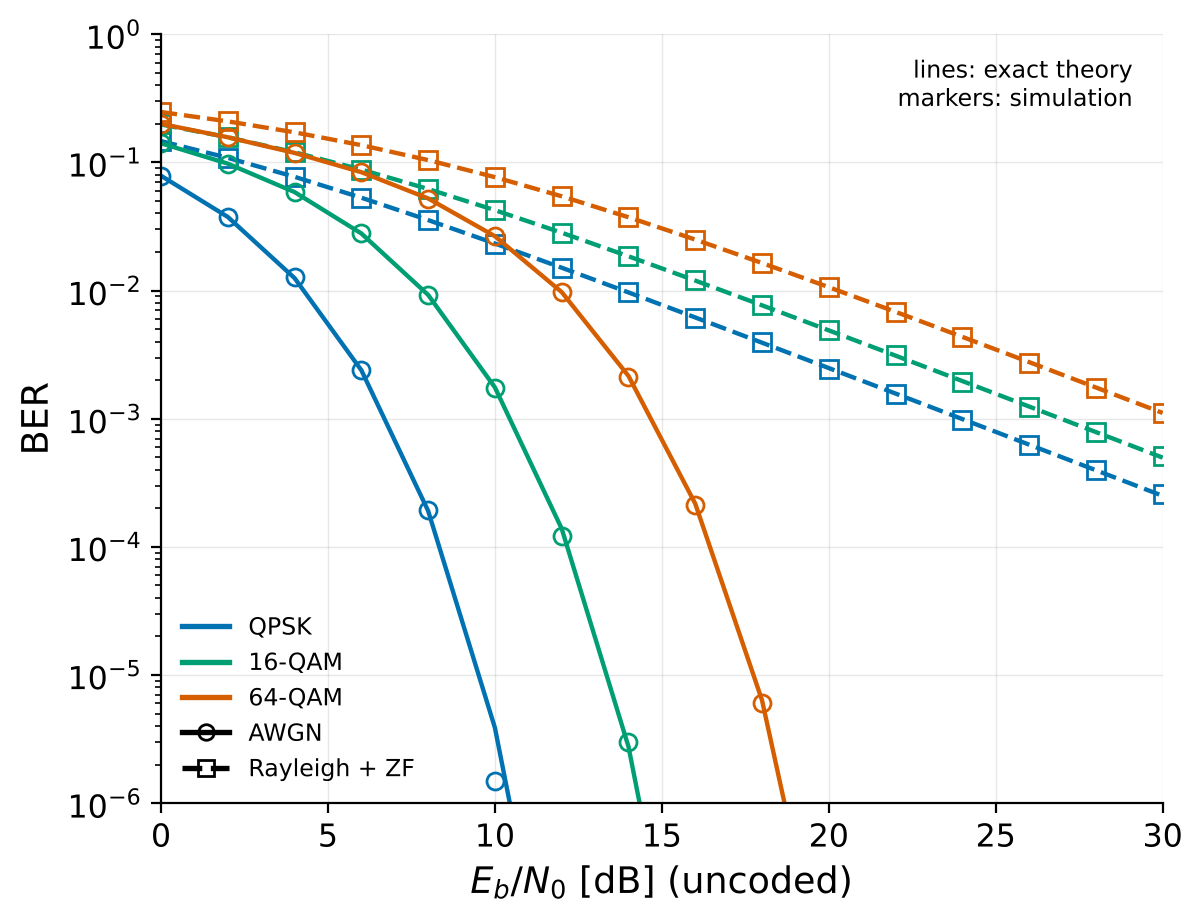

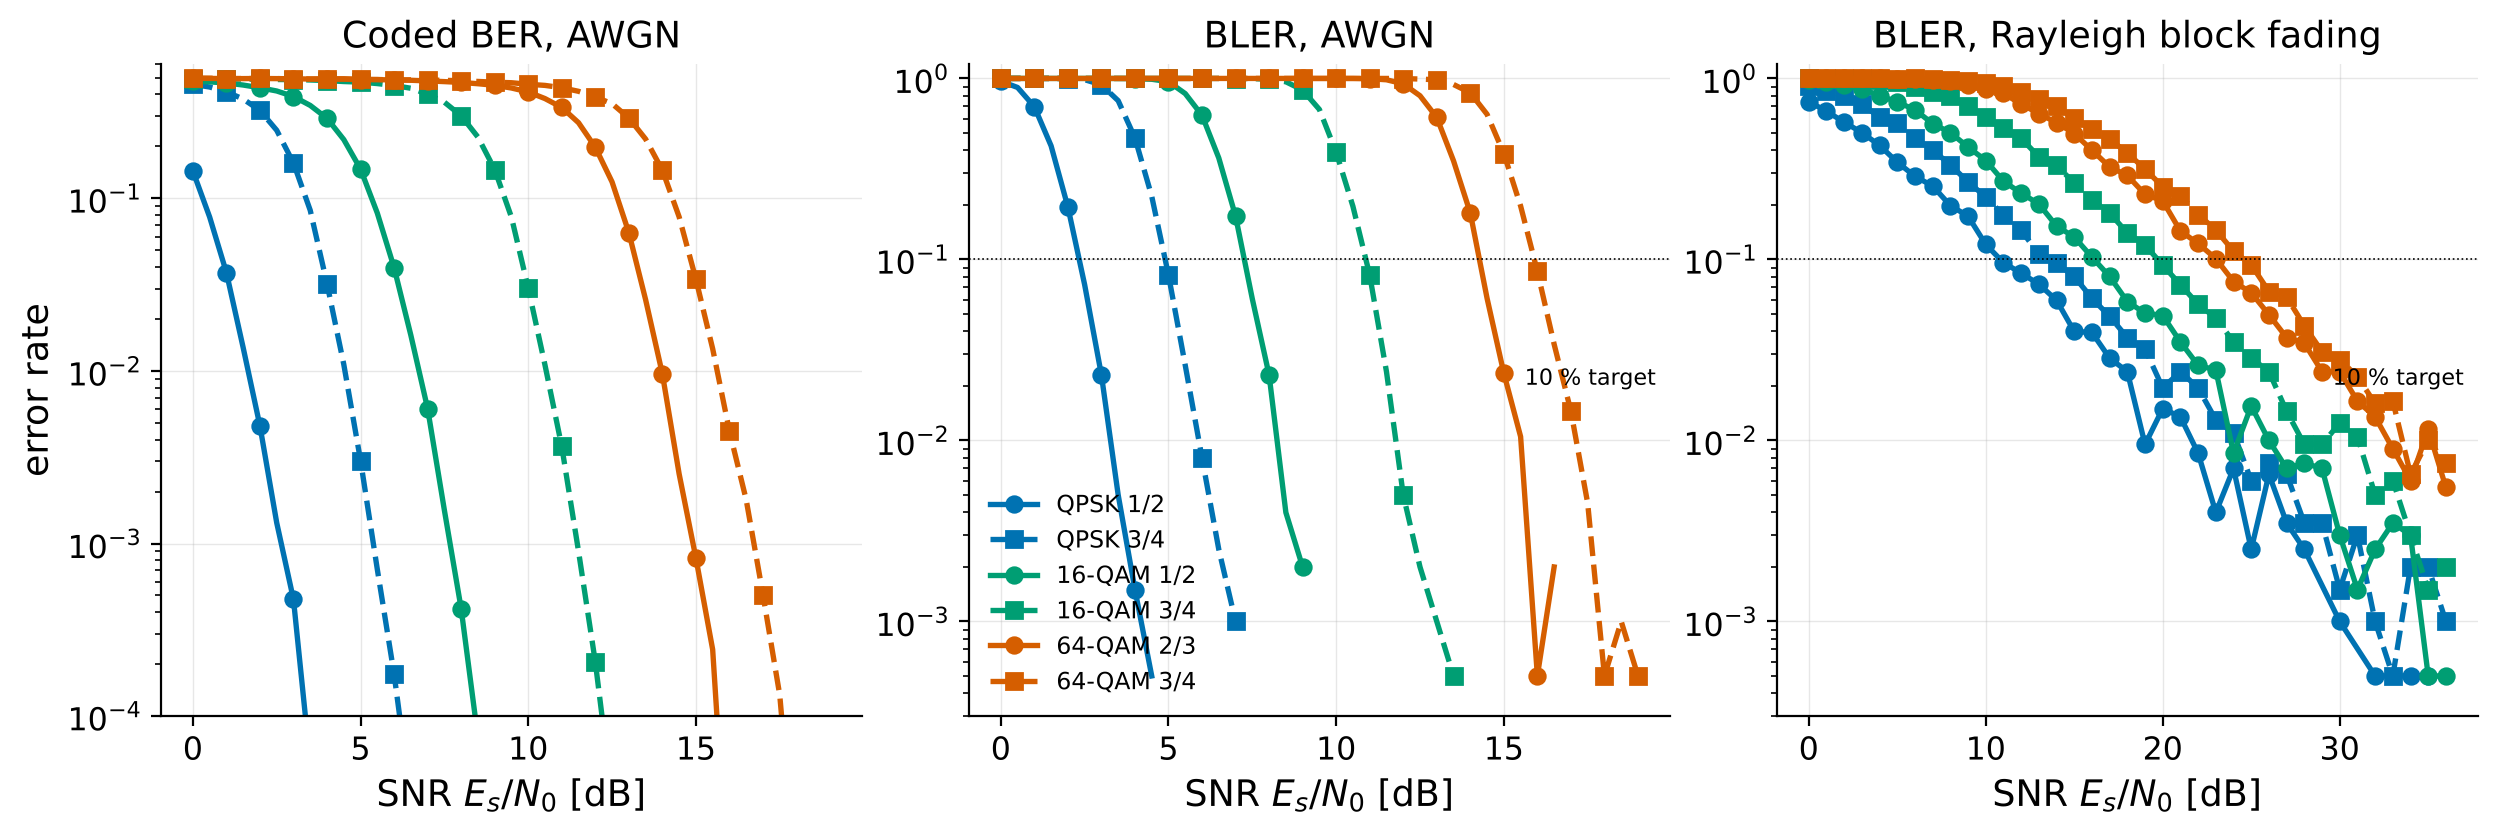

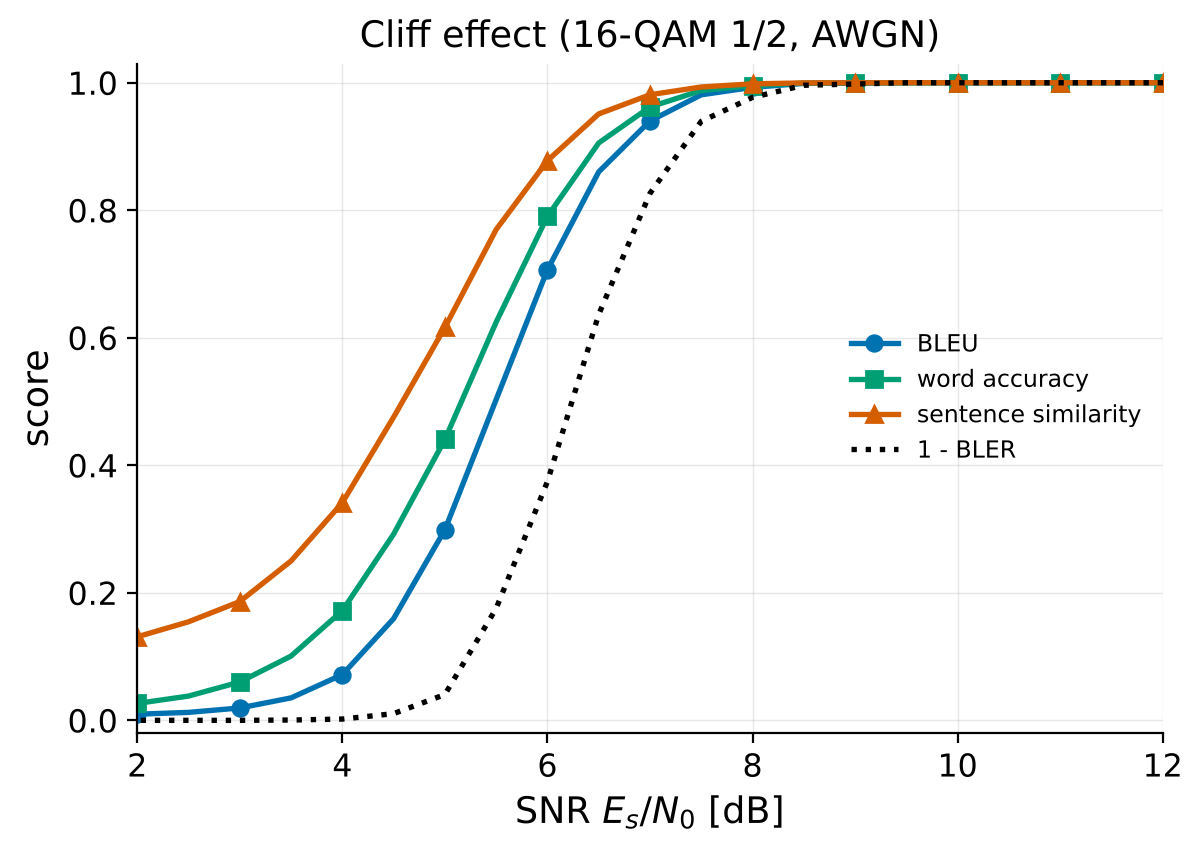

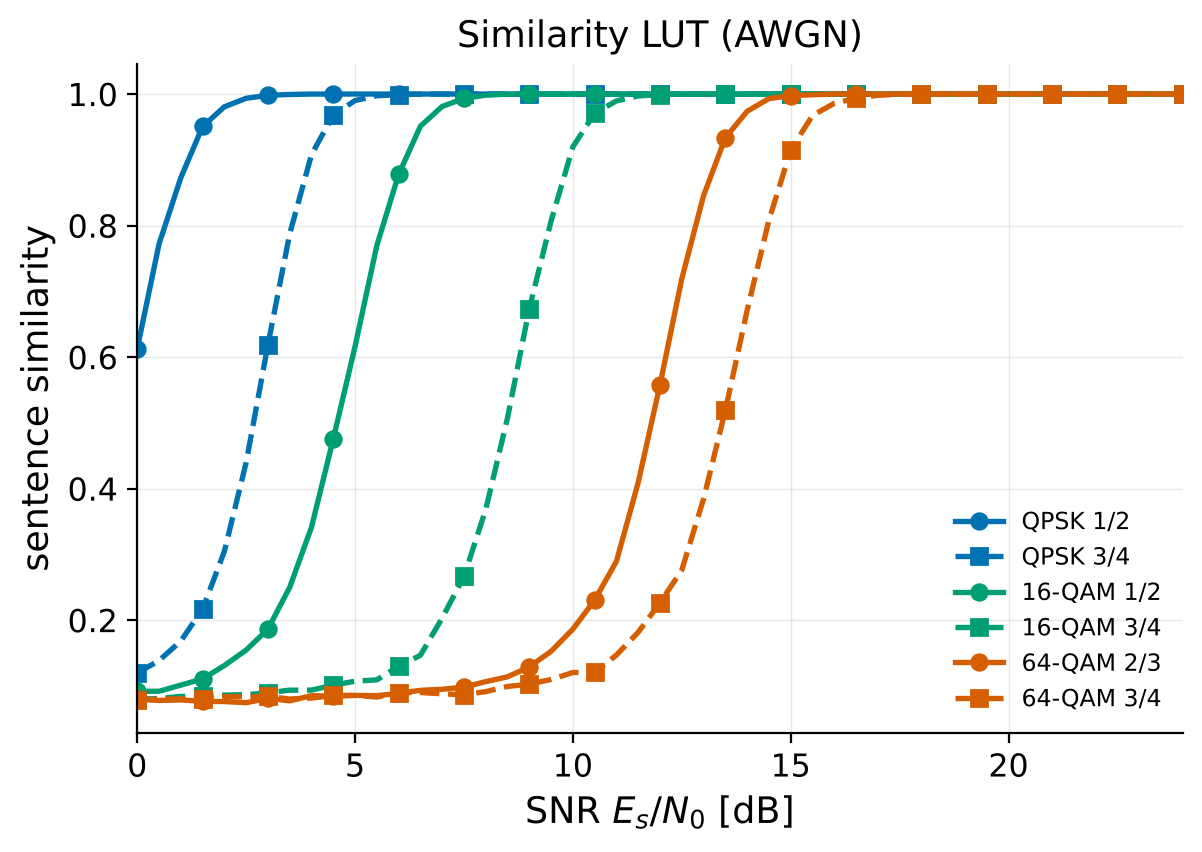

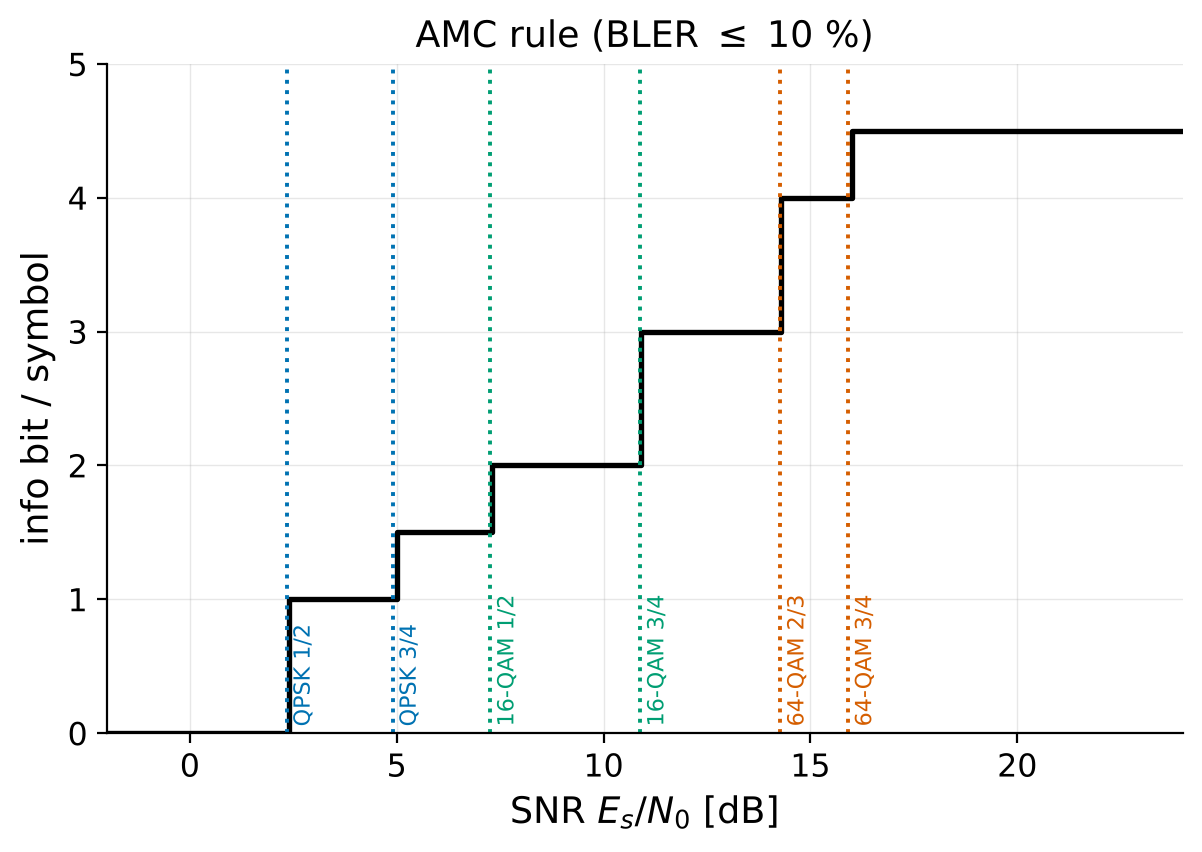

In [17]:
show("fig_ber_validation", "fig_coded_curves", "fig_text_quality", "fig_text_quality_all", "fig_amc", width=900)

## 4. Task 2 &mdash; autoencoder physical layer

`task2_autoencoder.py` implements an end-to-end autoencoder (O'Shea &amp; Hoydis): a message $s\in\{1..16\}$ ($k=4$ bits) &rarr; encoder DNN (16&rarr;64&rarr;64&rarr;$n$) &rarr; channel &rarr; decoder DNN with 16-way soft-max, trained by cross-entropy.

* noise per real channel use: $\sigma=(2R\,E_b/N_0)^{-1/2}$ with $R=k/n$; two energy constraints (average energy $n$, or constant energy $n$ per codeword);
* **(7,4) in AWGN** against uncoded BPSK blocks, Hamming(7,4) with hard decisions (syndrome) and Hamming(7,4) with ML decoding; additionally *ML decoding of the AE's own codebook*, which shows that the learned decoder cannot be better than ML;
* **(2,4)**: 16 messages on one complex symbol against 16-QAM, including the learned constellation;
* **(7,4) in Rayleigh fading with CSI at the receiver**: independent fade per channel use, decoder input $[\mathbf y,\mathbf h]$, ML baseline $\arg\max_c\sum_i h_iy_ic_i$.

In [18]:
%%module task2_autoencoder
"""
task2_autoencoder.py -- Task 2: deep-learning physical layer (end-to-end autoencoder).

Idea (O'Shea & Hoydis, 2017).  Treat transmitter + channel + receiver as ONE neural
network that is trained end to end:
    message s in {0..15} (k = 4 bits)
        -> encoder DNN -> n real channel uses x (power-normalised)
        -> channel (AWGN, or Rayleigh fading with receiver CSI)
        -> decoder DNN -> soft-max over the 16 messages
Loss = cross entropy between the soft-max output and the transmitted message, so the
network jointly invents a CODEBOOK (encoder) and a DECODER.  No bit-wise structure,
modulation or code is imposed.

Experiments
-----------
A. (7,4) AE in AWGN  vs  uncoded BPSK,  Hamming(7,4) + hard decision,
                          Hamming(7,4) + maximum-likelihood (soft) decoding.
B. (2,4) AE in AWGN  (16 messages on ONE complex symbol)  vs  16-QAM
   -> learned constellation vs 16-QAM.
C. (7,4) AE in Rayleigh fading with CSI at the receiver  vs the same baselines.

Conventions
-----------
* Eb/N0 is per INFORMATION bit.  With code rate R = k/n and real signalling
  (unit energy per real channel use on average) the noise std per real channel use is
        sigma = sqrt( 1 / (2 R Eb/N0) ) .
* Energy constraint: average over the 16 codewords  E||x||^2 = n  (the whole code-
  book is rescaled).  This is the average-power constraint of the system model, a
  *weaker* constraint than per-codeword constant energy, so the AE is free to beat
  a constant-energy code if such a code exists.
* Fading (C): h_i ~ Rayleigh, E[h^2]=1, independent for every channel use (ideal
  interleaving), receiver knows h_i (CSI); the decoder gets the vector [y, h].
* BLER = message (4-bit block) error probability.
"""
import os, json, time, itertools
import numpy as np
import torch
import torch.nn as nn
from scipy.special import erfc
from config import *

torch.set_num_threads(2)
DEV = "cpu"
K_BITS = 4
M_MSG = 1 << K_BITS


def Qf(x):
    return 0.5 * erfc(x / np.sqrt(2))


# ----------------------------------------------------------------------------- model
class AE(nn.Module):
    def __init__(self, n, hid=64, csi=False, const_energy=False):
        super().__init__()
        self.n, self.csi, self.const_energy = n, csi, const_energy
        self.enc = nn.Sequential(nn.Linear(M_MSG, hid), nn.ReLU(), nn.Linear(hid, hid), nn.ReLU(),
                                 nn.Linear(hid, n))
        din = 2 * n if csi else n
        self.dec = nn.Sequential(nn.Linear(din, hid * 2), nn.ReLU(), nn.Linear(hid * 2, hid), nn.ReLU(),
                                 nn.Linear(hid, M_MSG))
        self.register_buffer("eye", torch.eye(M_MSG))

    def codebook(self):
        """(16, n) codebook.  Two energy constraints are supported:
        * average  (default): rescaled so that the AVERAGE energy over the 16 codewords is n,
        * constant (const_energy=True): EVERY codeword has energy exactly n (all points on a
          sphere), the constraint of the original O'Shea-Hoydis autoencoder; Hamming(7,4)+BPSK
          satisfies it too, so this is the like-for-like comparison."""
        z = self.enc(self.eye)
        if self.const_energy:
            return z * torch.sqrt(self.n / (z ** 2).sum(1, keepdim=True))
        return z * torch.sqrt(self.n / (z ** 2).sum(1).mean())

    def channel(self, x, sigma, fading):
        if fading:
            h = torch.sqrt(torch.randn_like(x) ** 2 + torch.randn_like(x) ** 2) / np.sqrt(2.0)   # Rayleigh, E h^2 = 1
            y = h * x + sigma * torch.randn_like(x)
            return torch.cat([y, h], dim=-1)
        return x + sigma * torch.randn_like(x)

    def forward(self, idx, sigma, fading=False):
        x = self.codebook()[idx]
        return self.dec(self.channel(x, sigma, fading))


def sigma_of(ebn0_db, n, k=K_BITS):
    R = k / n
    return np.sqrt(1.0 / (2 * R * 10 ** (np.asarray(ebn0_db) / 10)))


def train_ae(n, fading=False, train_range=(0.0, 8.0), iters=AE_TRAIN_ITERS, seed=SEED, hid=64, tag="",
             const_energy=False):
    """Adam + cosine learning-rate decay; the training SNR is drawn per example in train_range."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = AE(n, hid=hid, csi=fading, const_energy=const_energy)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=iters, eta_min=1e-4)
    lossf = nn.CrossEntropyLoss()
    hist = []
    t0 = time.time()
    for it in range(iters):
        idx = torch.randint(0, M_MSG, (AE_BATCH,))
        eb = torch.empty(AE_BATCH, 1).uniform_(*train_range)
        sigma = torch.sqrt(1.0 / (2 * (K_BITS / n) * 10 ** (eb / 10)))
        loss = lossf(model(idx, sigma, fading), idx)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if it % 200 == 0 or it == iters - 1:
            hist.append((it, float(loss.detach())))
    print(f"[2] trained AE(n={n}, fading={fading}) {tag} in {time.time()-t0:.0f}s, final loss {hist[-1][1]:.4f}", flush=True)
    return model, hist


@torch.no_grad()
def ae_bler(model, ebn0_db, n_msgs, fading=False, seed=0):
    torch.manual_seed(seed)
    sigma = float(sigma_of(ebn0_db, model.n))
    errs, done = 0, 0
    while done < n_msgs:
        b = min(500_000, n_msgs - done)
        idx = torch.randint(0, M_MSG, (b,))
        pred = model(idx, sigma, fading).argmax(1)
        errs += int((pred != idx).sum()); done += b
    return errs / n_msgs


# ----------------------------------------------------------------------------- baselines
def hamming74_codebook():
    """Systematic Hamming(7,4): codeword = [d1 d2 d3 d4 p1 p2 p3] (any equivalent code gives the same curves)."""
    P = np.array([[1, 1, 0], [1, 0, 1], [0, 1, 1], [1, 1, 1]])
    msgs = np.array(list(itertools.product([0, 1], repeat=4)))
    cw = np.concatenate([msgs, (msgs @ P) % 2], axis=1)
    return cw.astype(np.float32)                              # (16, 7) in {0,1}


@torch.no_grad()
def hamming_blers(ebn0_db, n_msgs, fading=False, seed=0):
    """
    Simulated BLER of Hamming(7,4)+BPSK for hard decision and ML (soft) decoding,
    and of uncoded BPSK blocks of 4 bits.  Same noise/fading statistics as the AE.
    """
    g = torch.Generator().manual_seed(seed)
    cw = torch.tensor(hamming74_codebook())
    cwb = 1 - 2 * cw                                           # BPSK: bit 0 -> +1
    sigma = float(sigma_of(ebn0_db, 7))
    sigma_u = float(sigma_of(ebn0_db, 4))                      # uncoded: n = k = 4, R = 1
    e_h = e_m = e_u = 0; done = 0
    while done < n_msgs:
        b = min(400_000, n_msgs - done)
        idx = torch.randint(0, M_MSG, (b,), generator=g)
        x = cwb[idx]
        noise = sigma * torch.randn(b, 7, generator=g)
        if fading:
            h = torch.sqrt(torch.randn(b, 7, generator=g) ** 2 + torch.randn(b, 7, generator=g) ** 2) / np.sqrt(2.0)
        else:
            h = torch.ones(b, 7)
        y = h * x + noise
        # ML with CSI: min ||y - h c||^2  <=>  max  sum h y c   (all |c_i| = 1)
        e_m += int((torch.argmax((h * y) @ cwb.T, 1) != idx).sum())
        # hard decision: bit decisions, then nearest codeword in Hamming distance (= syndrome decoding)
        hard = (y < 0).float()
        dH = (hard[:, None, :] != cw[None, :, :]).sum(2)
        e_h += int((torch.argmin(dH, 1) != idx).sum())
        # uncoded: 4 independent BPSK bits, coherent detection
        ub = torch.randint(0, 2, (b, 4), generator=g).float()
        hu = (torch.sqrt(torch.randn(b, 4, generator=g) ** 2 + torch.randn(b, 4, generator=g) ** 2) / np.sqrt(2.0)) if fading else torch.ones(b, 4)
        yu = hu * (1 - 2 * ub) + sigma_u * torch.randn(b, 4, generator=g)
        e_u += int(((yu < 0).float() != ub).any(1).sum())
        done += b
    return e_h / n_msgs, e_m / n_msgs, e_u / n_msgs


def uncoded_bpsk_theory(ebn0_db, fading=False, k=4):
    g = 10 ** (np.asarray(ebn0_db) / 10)
    p = 0.5 * (1 - np.sqrt(g / (1 + g))) if fading else Qf(np.sqrt(2 * g))
    return 1 - (1 - p) ** k


def hamming_hard_theory(ebn0_db, fading=False):
    """BLER = 1 - [(1-p)^7 + 7 p (1-p)^6]  with p the raw BPSK bit error probability at Eb/N0 * 4/7."""
    g = 10 ** (np.asarray(ebn0_db) / 10) * 4 / 7
    p = 0.5 * (1 - np.sqrt(g / (1 + g))) if fading else Qf(np.sqrt(2 * g))
    return 1 - ((1 - p) ** 7 + 7 * p * (1 - p) ** 6)


# ----------------------------------------------------------------------------- (2,4) vs 16-QAM
def qam16_points_real2():
    """Gray-free 16-QAM in R^2 scaled so that E||x||^2 = n = 2 (same convention as the AE)."""
    lv = np.array([-3, -1, 1, 3], float)
    pts = np.array([(a, b) for a in lv for b in lv])
    return pts * np.sqrt(2.0 / np.mean((pts ** 2).sum(1)))


@torch.no_grad()
def qam16_ser(ebn0_db, n_msgs, seed=0):
    g = torch.Generator().manual_seed(seed)
    pts = torch.tensor(qam16_points_real2(), dtype=torch.float32)
    sigma = float(sigma_of(ebn0_db, 2))
    errs, done = 0, 0
    while done < n_msgs:
        b = min(500_000, n_msgs - done)
        idx = torch.randint(0, M_MSG, (b,), generator=g)
        y = pts[idx] + sigma * torch.randn(b, 2, generator=g)
        errs += int((torch.cdist(y, pts).argmin(1) != idx).sum()); done += b
    return errs / n_msgs


@torch.no_grad()
def ae_ml_ser(model, ebn0_db, n_msgs, seed=0):
    """ML (nearest-neighbour) detection on the AE's *own* codebook (any n): the lower bound on the
    error probability of ANY decoder for that codebook, so the learned decoder can only approach it."""
    g = torch.Generator().manual_seed(seed)
    pts = model.codebook()
    sigma = float(sigma_of(ebn0_db, model.n))
    errs, done = 0, 0
    while done < n_msgs:
        b = min(500_000, n_msgs - done)
        idx = torch.randint(0, M_MSG, (b,), generator=g)
        y = pts[idx] + sigma * torch.randn(b, model.n, generator=g)
        errs += int((torch.cdist(y, pts).argmin(1) != idx).sum()); done += b
    return errs / n_msgs


def min_dist2(cb):
    d = torch.cdist(cb, cb) ** 2 + torch.eye(len(cb)) * 1e9
    return float(d.min())



def add_const_energy(res):
    """Extra AEs with the per-codeword (constant) energy constraint, (7,4) AWGN and Rayleigh+CSI."""
    NM = AE_EVAL_MSGS
    A, C = res["awgn_7_4"], res["rayleigh_7_4"]
    ae, _ = train_ae(7, fading=False, train_range=(0.0, 8.0), const_energy=True, tag="(const. energy)")
    A["ae_const"] = [ae_bler(ae, e, NM) for e in A["ebn0"]]
    cb = ae.codebook().detach()
    A["ae_const_min_dist2"] = min_dist2(cb)
    aef, _ = train_ae(7, fading=True, train_range=(4.0, 16.0), hid=96, const_energy=True, tag="(Rayleigh+CSI, const. energy)")
    C["ae_const"] = [ae_bler(aef, e, NM, fading=True) for e in C["ebn0"]]
    return res

# ----------------------------------------------------------------------------- main
def main():
    res = {}
    grid = [float(x) for x in AE_EBN0_GRID]
    NM = AE_EVAL_MSGS
    t0 = time.time()

    # --- A: (7,4) AWGN
    ae74, hist74 = train_ae(7, fading=False, train_range=(0.0, 8.0))
    A = dict(ebn0=grid, ae=[], ham_hard=[], ham_ml=[], uncoded=[], ham_hard_theory=[], uncoded_theory=[])
    for e in grid:
        A["ae"].append(ae_bler(ae74, e, NM))
        hh, hm, uu = hamming_blers(e, NM)
        A["ham_hard"].append(hh); A["ham_ml"].append(hm); A["uncoded"].append(uu)
        A["ham_hard_theory"].append(float(hamming_hard_theory(e)))
        A["uncoded_theory"].append(float(uncoded_bpsk_theory(e)))
    A["ae_ml_own"] = [ae_ml_ser(ae74, e, NM) for e in grid]          # ML on the AE's own codebook
    cb = ae74.codebook().detach()
    cwb = torch.tensor(1 - 2 * hamming74_codebook())
    A["ae_min_dist2"] = min_dist2(cb)
    A["hamming_min_dist2"] = min_dist2(cwb)
    A["ae_codeword_energy_std"] = float((cb ** 2).sum(1).std())
    A["loss_hist"] = hist74
    res["awgn_7_4"] = A
    torch.save(ae74.state_dict(), os.path.join(DATA_DIR, "ae_7_4_awgn.pt"))

    # --- B: (2,4) AWGN
    ae24, hist24 = train_ae(2, fading=False, train_range=(4.0, 12.0), hid=64)
    gridB = [float(x) for x in np.arange(0.0, 14.1, 1.0)]
    B = dict(ebn0=gridB, ae=[], ae_ml=[], qam16=[])
    for e in gridB:
        B["ae"].append(ae_bler(ae24, e, NM)); B["ae_ml"].append(ae_ml_ser(ae24, e, NM)); B["qam16"].append(qam16_ser(e, NM))
    B["ae_points"] = ae24.codebook().detach().numpy().tolist()
    B["qam_points"] = qam16_points_real2().tolist()
    B["ae_min_dist2"] = min_dist2(ae24.codebook().detach())
    B["qam_min_dist2"] = min_dist2(torch.tensor(qam16_points_real2(), dtype=torch.float32))
    B["loss_hist"] = hist24
    res["awgn_2_4"] = B
    torch.save(ae24.state_dict(), os.path.join(DATA_DIR, "ae_2_4_awgn.pt"))

    # --- C: (7,4) Rayleigh with CSI
    aef, histf = train_ae(7, fading=True, train_range=(4.0, 16.0), hid=96, tag="(Rayleigh+CSI)")
    gridC = [float(x) for x in np.arange(0.0, 24.1, 2.0)]
    C = dict(ebn0=gridC, ae=[], ham_hard=[], ham_ml=[], uncoded=[], ham_hard_theory=[], uncoded_theory=[])
    for e in gridC:
        C["ae"].append(ae_bler(aef, e, NM, fading=True))
        hh, hm, uu = hamming_blers(e, NM, fading=True)
        C["ham_hard"].append(hh); C["ham_ml"].append(hm); C["uncoded"].append(uu)
        C["ham_hard_theory"].append(float(hamming_hard_theory(e, True)))
        C["uncoded_theory"].append(float(uncoded_bpsk_theory(e, True)))
    C["loss_hist"] = histf
    res["rayleigh_7_4"] = C
    torch.save(aef.state_dict(), os.path.join(DATA_DIR, "ae_7_4_rayleigh.pt"))

    add_const_energy(res)
    with open(os.path.join(RES_DIR, "task2_results.json"), "w") as f:
        json.dump(res, f)
    print(f"[task2] done in {time.time()-t0:.0f}s")
    # headline numbers
    i = grid.index(6.0) if 6.0 in grid else 8
    print(f"[2A] Eb/N0={grid[i]} dB: AE {A['ae'][i]:.2e} | Ham-ML {A['ham_ml'][i]:.2e} | Ham-hard {A['ham_hard'][i]:.2e} | uncoded {A['uncoded'][i]:.2e}")
    print(f"[2A] d_min^2: AE {A['ae_min_dist2']:.2f} vs Hamming {A['hamming_min_dist2']:.2f}; AE codeword energy std {A['ae_codeword_energy_std']:.3f}")
    print(f"[2B] d_min^2: AE {B['ae_min_dist2']:.3f} vs 16QAM {B['qam_min_dist2']:.3f}")


if __name__ == "__main__":
    import sys
    if "--extras" in sys.argv:          # only add the constant-energy variants to an existing result file
        p = os.path.join(RES_DIR, "task2_results.json")
        r = add_const_energy(json.load(open(p)))
        json.dump(r, open(p, "w"))
    else:
        main()


In [19]:
if RUN_MODE != "load":
    task2_autoencoder.main()
else:
    print("load mode: using saved Task-2 results in", config.RES_DIR)

load mode: using saved Task-2 results in /home/claude/ex1/results


In [20]:
R2 = json.load(open(os.path.join(config.RES_DIR, "task2_results.json")))
def at(d, e, key): 
    i = int(np.argmin(np.abs(np.array(d["ebn0"]) - e))); return d[key][i]
a, c = R2["awgn_7_4"], R2["rayleigh_7_4"]
print("(7,4) in AWGN, BLER at Eb/N0 = 6 dB")
for k, lab in [("uncoded", "uncoded BPSK"), ("ham_hard", "Hamming hard"), ("ham_ml", "Hamming ML"),
               ("ae", "AE (avg. energy)"), ("ae_const", "AE (const. energy)"), ("ae_ml_own", "ML on AE codebook")]:
    if k in a: print(f"   {lab:20s} {at(a, 6.0, k):.2e}")
print(f"   min distance^2: AE {a['ae_min_dist2']:.2f} vs Hamming {a['hamming_min_dist2']:.2f}")
b = R2["awgn_2_4"]
print("\n(2,4) symbol error rate at Eb/N0 = 10 dB:  AE %.2e | AE-ML %.2e | 16-QAM %.2e" % (at(b,10,"ae"), at(b,10,"ae_ml"), at(b,10,"qam16")))
print("   min distance^2: AE %.2f vs 16-QAM %.2f" % (b["ae_min_dist2"], b["qam_min_dist2"]))
print("\n(7,4) in Rayleigh with CSI, BLER")
for e in (10.0, 14.0):
    print(f"   {e:4.0f} dB:  Hamming ML {at(c,e,'ham_ml'):.2e}   AE {at(c,e,'ae'):.2e}   ratio {at(c,e,'ham_ml')/max(at(c,e,'ae'),1e-12):.1f}x")

(7,4) in AWGN, BLER at Eb/N0 = 6 dB
   uncoded BPSK         9.46e-03
   Hamming hard         5.44e-03
   Hamming ML           8.21e-04
   AE (avg. energy)     7.05e-04
   AE (const. energy)   7.64e-04
   ML on AE codebook    6.92e-04
   min distance^2: AE 11.77 vs Hamming 12.00

(2,4) symbol error rate at Eb/N0 = 10 dB:  AE 4.89e-03 | AE-ML 4.85e-03 | 16-QAM 7.01e-03
   min distance^2: AE 0.71 vs 16-QAM 0.80

(7,4) in Rayleigh with CSI, BLER
     10 dB:  Hamming ML 4.02e-03   AE 1.46e-03   ratio 2.8x
     14 dB:  Hamming ML 3.10e-04   AE 3.35e-05   ratio 9.3x


**Why the AE approaches but does not exceed ML decoding.** For a *fixed* codebook the maximum-likelihood decoder minimises the block error probability, so no decoder can beat it; the learned decoder reaches it (compare `ae` with `ae_ml_own`). Gains over Hamming(7,4) therefore come from the *codebook* (jointly optimised for the operating SNR, and diversity in fading), not from the decoder.

**What limits longer blocks.** The AE treats each message as one of $2^k$ classes: output size, training samples and the codebook search grow exponentially ($k=32$ gives $4\cdot10^9$ classes), and exact ML needs to enumerate all codewords. Practical designs need structure (convolutional, turbo or polar-style AEs, bit-wise soft outputs).

### 4.1 Figures of Task 2
(7,4) in AWGN, (7,4) in Rayleigh with CSI, learned (2,4) constellation, (2,4) symbol error rate and the training curves.

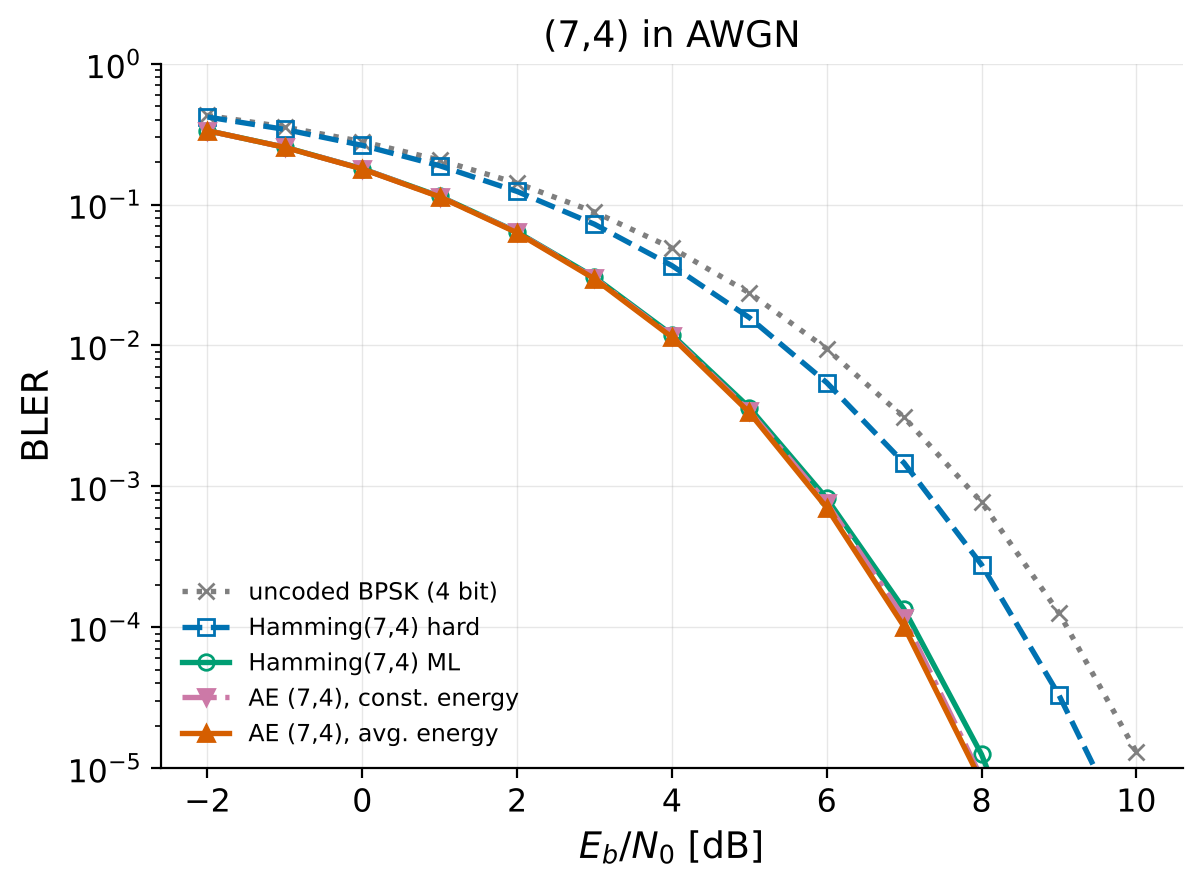

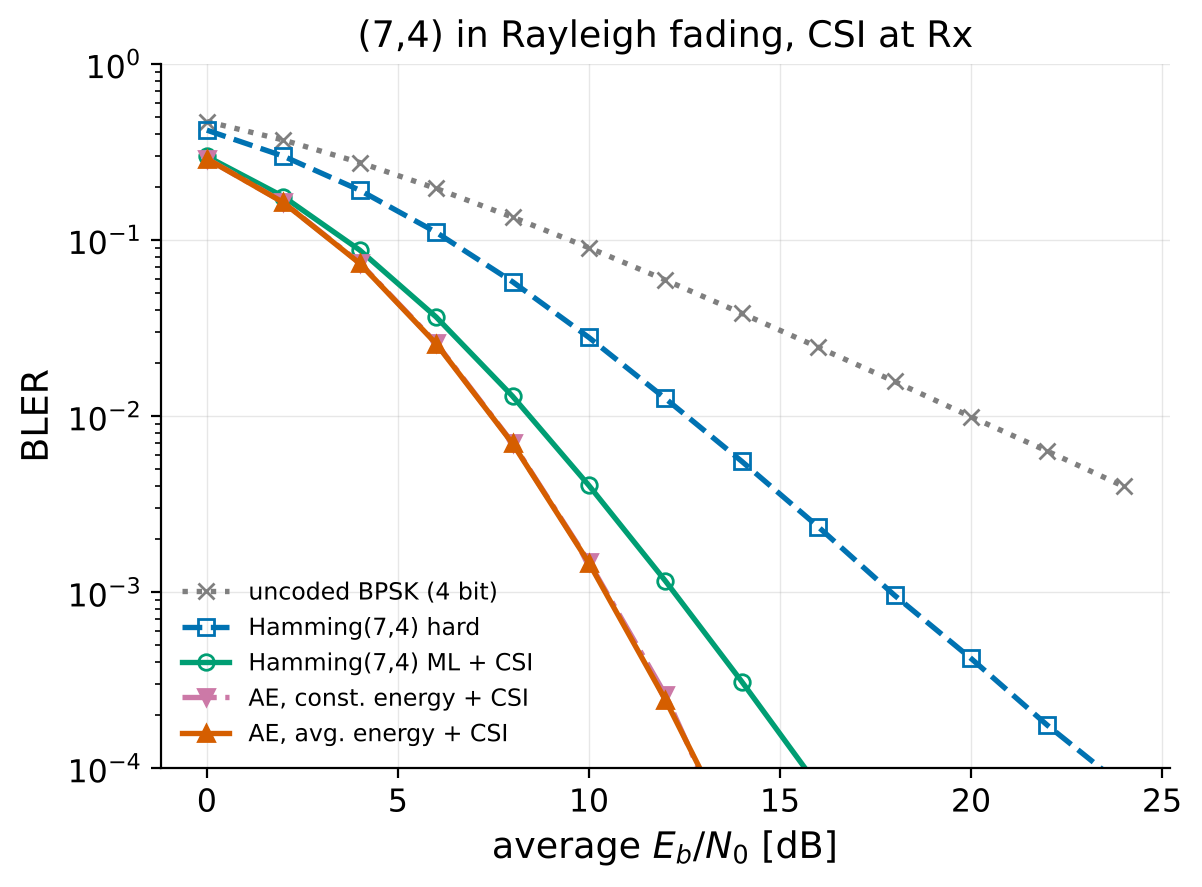

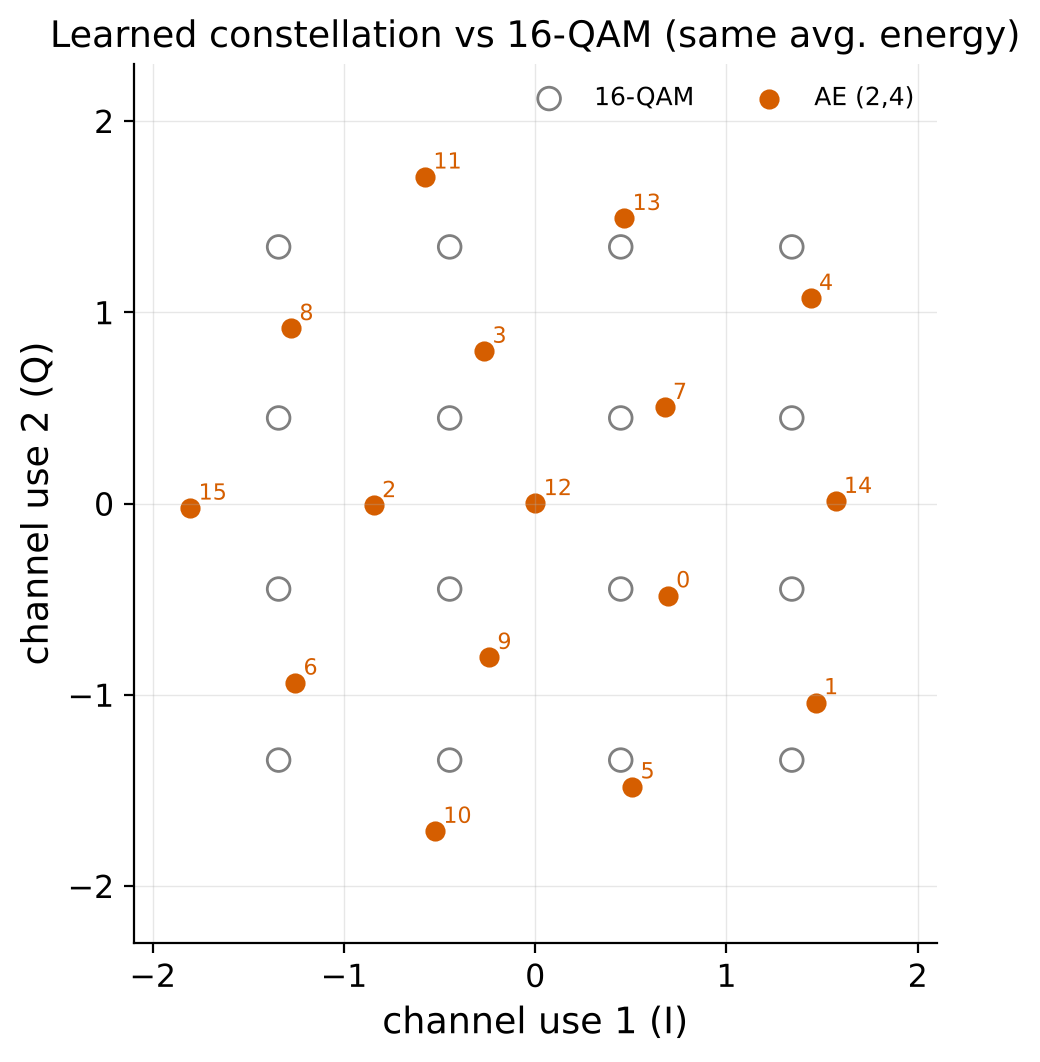

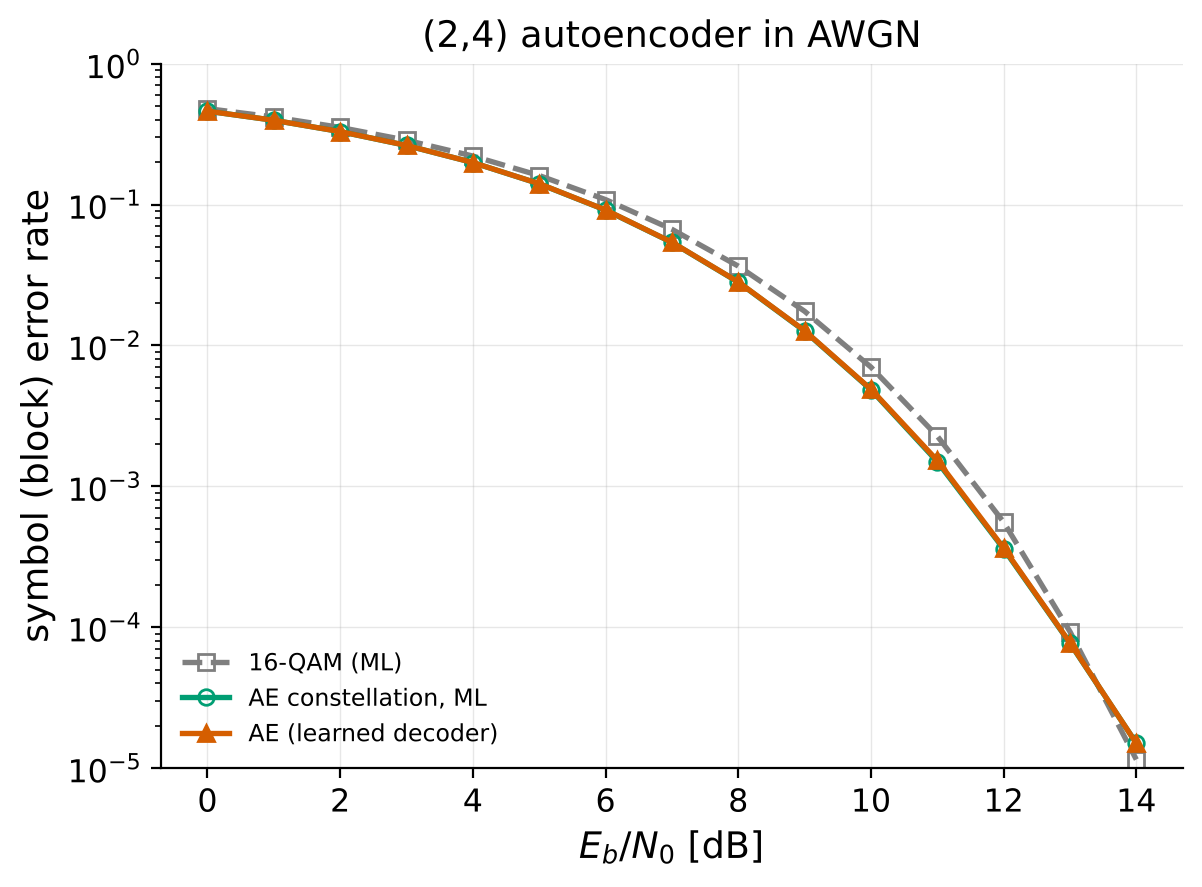

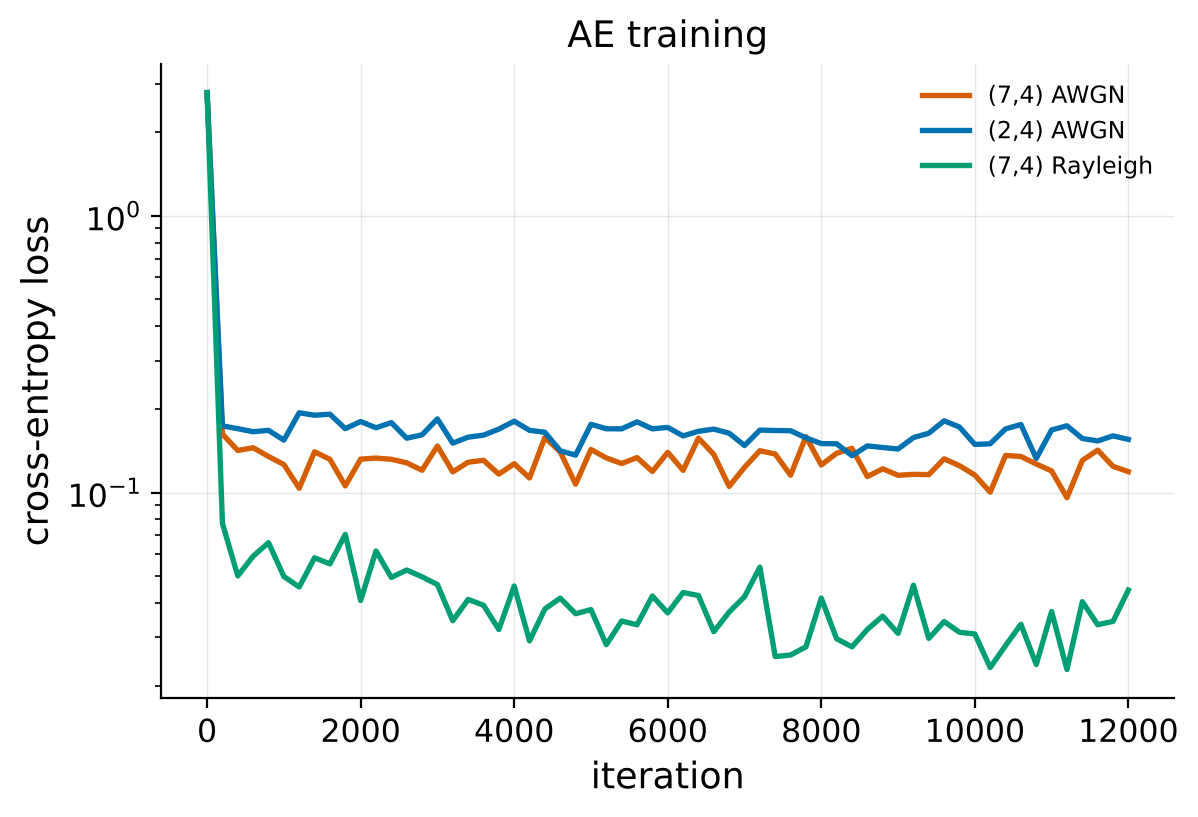

In [21]:
show("fig_ae_awgn", "fig_ae_rayleigh", "fig_constellation", "fig_ae24_ser", "fig_ae_training", width=760)

## 5. Task 3 &mdash; multi-user resource allocation with deep learning

**System:** U=8 users, N=16 RBs of B=180 kHz in a 500 m cell (min. distance 35 m), path loss 128.1+37.6 log<sub>10</sub>(d/km) dB, 8 dB shadowing, independent Rayleigh fading per RB, noise &minus;174 dBm/Hz with F=9 dB. SNR of user u on RB n: $\gamma_{u,n}=p_n a_{u,n}$.

**Problem:** maximise $\sum_{u,n}x_{u,n}B\log_2(1+\gamma_{u,n})$ s.t. one user per RB, $\sum_n p_n\le P_{\max}$ and $R_u\ge R_{\min}=1$ Mbit/s.

* **`resource_alloc.py`** &mdash; drops, rates, metrics (sum rate, % users meeting R<sub>min</sub>, Jain index, 5th-percentile rate) and the **four benchmarks**: (1) round-robin + equal power; (2) strongest user per RB + water-filling; (3) *exact MILP* (`scipy.optimize.milp`/HiGHS) + equal power; (4) MILP assignment + **KKT water-filling that respects R<sub>min</sub>**: $p_n=[\ell_{u(n)}-1/a_n]^+$ with $\ell_u=\max(\ell,\ell_u^{\min})$, both levels found by bisection; infeasible drops use admission control.
* **`dnn_ra.py`** &mdash; **unsupervised learning-to-optimise (L2O)**: a permutation-equivariant network (shared weights across users and RBs) outputs assignment logits (soft-max over users per RB, arg-max at test time through a straight-through estimator) and a power split $p_n=P_{\max}\,\mathrm{softmax}(w)_n$, so all constraints except R<sub>min</sub> hold by construction. Loss $=-\sum x R+\rho\sum_u[R_{\min}-R_u]_+^2$, no labels, fresh random drops and P<sub>max</sub>&sim;U[15,40] dBm at every step. The **hybrid** keeps the DNN assignment and recomputes powers by KKT water-filling.
* **`task3_ra.py`** &mdash; sweeps P<sub>max</sub> = 15&hellip;40 dBm over common drops, measures every metric and computation time, and applies the **Task-1 AMC rule** to each allocated RB: correct sentences per second $s_{u,n}=\frac{B}{S_m}(1-\mathrm{BLER}_m(\gamma_{u,n}))$.

In [22]:
%%module resource_alloc
"""
resource_alloc.py -- Task 3: system model, metrics and the four classical benchmarks
for the joint RB-assignment / power-allocation problem

    max   sum_u sum_n x_{u,n} B log2(1 + gamma_{u,n})
    s.t.  sum_u x_{u,n} <= 1 (each RB serves at most one user),
          sum_n p_n <= Pmax,   R_u = sum_n x_{u,n} B log2(1+gamma_{u,n}) >= Rmin  for all u,
    gamma_{u,n} = p_n g_{u,n} / (N0 B F)  =  p_n a_{u,n}.

Notation used below: a[u,n] = g[u,n]/(N0 B F) is the "SNR per watt" of user u on RB n
(unit 1/W), p_n in watts, batches of D independent channel realisations ("drops")
have shape (D, U, N).

Benchmarks (all return a hard assignment X (D,U,N) in {0,1} and a power vector p (D,N)):
  1. round_robin          : RB n -> user (n mod U), equal power Pmax/N
  2. strongest_wf         : each RB to its strongest user, classical water-filling
  3. milp_equal           : exact MILP assignment (with Rmin), equal power
  4. milp_kkt_wf          : MILP assignment + water-filling that respects Rmin (KKT)

KKT derivation of benchmark 4 (explained in the paper too)
----------------------------------------------------------
For a FIXED assignment (RB n owned by user u(n)) the power problem
    max_p  sum_n B log2(1 + p_n a_n)   s.t.  sum_n p_n <= P,
           R_u(p) = sum_{n in S_u} B log2(1 + p_n a_n) >= Rmin  for all u,   p >= 0
is convex (concave objective, convex constraints).  With multipliers mu >= 0 for the
power budget and lambda_u >= 0 for the rate constraints the Lagrangian is
    L = sum_n (1 + lambda_{u(n)}) B log2(1+p_n a_n) - mu (sum_n p_n - P) - sum_u lambda_u (...).
Stationarity  dL/dp_n = 0  gives a USER-DEPENDENT water-filling
    p_n = [ l_{u(n)} - 1/a_n ]^+ ,        l_u = (1 + lambda_u) B / (mu ln 2).
Complementary slackness: lambda_u > 0 only if R_u = Rmin.  Hence
    l_u = max( l , l_u^min ),
where l = B/(mu ln 2) is the common ("unconstrained") water level and l_u^min is the
smallest level that lets user u reach Rmin on its own RBs (found by bisection since
R_u(l_u) = sum_{n in S_u} B log2(max(1, l_u a_n)) is increasing in l_u).  The common
level l is then found by bisection so that sum_n p_n = Pmax.  If even l = 0 needs more
power than Pmax (sum_n [l_u^min - 1/a_n]^+ > Pmax) the problem is infeasible; then users
are admitted in increasing order of the power they need (admission control, maximising the
number of users that reach Rmin) and the rest of the budget is water-filled.
"""
import time
import numpy as np
from scipy.optimize import milp, LinearConstraint, Bounds
from config import *

LOG2E = 1.0 / np.log(2.0)


# ----------------------------------------------------------------------------- system model
def noise_power_w():
    """N0 * B * F in watts  (-174 dBm/Hz, 180 kHz, F = 9 dB  ->  about -112.5 dBm)."""
    return 10 ** ((NOISE_PSD_DBM_HZ + 10 * np.log10(B_RB) + NOISE_FIGURE_DB - 30.0) / 10.0)


def dbm_to_w(p_dbm):
    return 10 ** ((p_dbm - 30.0) / 10.0)


def generate_drops(rng, D):
    """
    D independent drops of the cell.  Returns a (D,U,N) array of linear SNR-per-watt
    values a = g/(N0 B F), where g = path loss * shadowing * |Rayleigh|^2:
      * users uniform in the annulus 35 m .. 500 m (uniform in AREA: r = sqrt(U(r0^2,R^2)))
      * path loss = 128.1 + 37.6 log10(d / 1 km)  dB
      * log-normal shadowing, 8 dB std, one value per user (same on all RBs)
      * Rayleigh small-scale fading: |h|^2 ~ Exp(1), independent per user AND per RB
    """
    r = np.sqrt(rng.uniform(MIN_DIST_M ** 2, CELL_RADIUS_M ** 2, size=(D, U)))
    pl_db = PL_A_DB + PL_B_DB * np.log10(r / 1000.0)
    sh_db = rng.normal(0.0, SHADOW_STD_DB, size=(D, U))
    large_scale = 10 ** (-(pl_db + sh_db) / 10.0)                      # (D,U)
    fading = rng.exponential(1.0, size=(D, U, N))                      # |h|^2
    g = large_scale[:, :, None] * fading
    return g / noise_power_w()


def rb_rates(a, p):
    """Rate of every (u,n) pair if it were allocated power p_n:  B log2(1 + p_n a_un)  [bit/s]."""
    return B_RB * np.log2(1.0 + p[:, None, :] * a)


def user_rates(X, a, p):
    return (X * rb_rates(a, p)).sum(axis=2)                             # (D,U)


# ----------------------------------------------------------------------------- metrics
def jain(R):
    s1, s2 = R.sum(1), (R ** 2).sum(1)
    return np.where(s2 > 0, s1 ** 2 / (R.shape[1] * np.maximum(s2, 1e-30)), 1.0)


def metrics(R):
    """R: (D,U) user rates [bit/s] -> dict of the five performance metrics (rate part)."""
    return dict(sum_rate_mbps=float(R.sum(1).mean() / 1e6),
                pct_users_rmin=float(100.0 * np.mean(R >= R_MIN * (1 - 1e-6))),
                jain=float(jain(R).mean()),
                p5_rate_mbps=float(np.percentile(R, 5) / 1e6))


# ----------------------------------------------------------------------------- benchmarks 1 & 2
def equal_power(D, P):
    return np.full((D, N), P / N)


def round_robin(a, P):
    D = a.shape[0]
    X = np.zeros((D, U, N))
    for n in range(N):
        X[:, n % U, n] = 1.0
    return X, equal_power(D, P)


def strongest_assign(a):
    D = a.shape[0]
    X = np.zeros((D, U, N))
    best = a.argmax(axis=1)                                            # (D,N) strongest user per RB
    np.put_along_axis(X, best[:, None, :], 1.0, axis=1)
    return X


def waterfill(a_sel, P, iters=70):
    """
    Classical water-filling  p_n = [l - 1/a_n]^+,  sum p_n = P  (bisection on l).
    a_sel: (D,N) SNR-per-watt of the user chosen on each RB (<=0 or inf-free).
    """
    inv = 1.0 / np.maximum(a_sel, 1e-30)
    lo = np.zeros(a_sel.shape[0]); hi = P + inv.max(axis=1)
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        tot = np.maximum(mid[:, None] - inv, 0).sum(1)
        big = tot > P
        hi = np.where(big, mid, hi); lo = np.where(big, lo, mid)
    return np.maximum(0.5 * (lo + hi)[:, None] - inv, 0)


def strongest_wf(a, P):
    X = strongest_assign(a)
    return X, waterfill((X * a).sum(1), P)


# ----------------------------------------------------------------------------- benchmark 3 (MILP)
def milp_assign_one(a1, P, kappa=10.0, time_limit=20.0):
    """
    Exact joint-assignment MILP for ONE drop (a1: (U,N)) with equal power Pmax/N:
        max  sum x_un r_un - kappa * sum_u s_u
        s.t. sum_u x_un <= 1 ;  sum_n r_un x_un + s_u >= Rmin ;  x binary, s >= 0
    r_un = B log2(1 + (P/N) a_un) / 1e6 [Mbit/s].  The slack s_u (penalised by kappa)
    keeps the problem feasible when equal power cannot give every user Rmin; if the
    instance is feasible the optimum has s = 0 and is the exact constrained optimum.
    """
    r = (B_RB * np.log2(1.0 + (P / N) * a1) / 1e6)                     # (U,N)
    nv = U * N + U
    c = np.concatenate([-r.ravel(), kappa * np.ones(U)])
    A = np.zeros((N + U, nv))
    for n in range(N):                                                  # one user per RB
        A[n, [u * N + n for u in range(U)]] = 1.0
    lb = np.full(N + U, -np.inf)
    ub = np.concatenate([np.ones(N), np.full(U, np.inf)])
    for u in range(U):                                                  # rate constraints (as >=)
        A[N + u, u * N:(u + 1) * N] = r[u]
        A[N + u, U * N + u] = 1.0
        lb[N + u] = R_MIN / 1e6
    integrality = np.concatenate([np.ones(U * N), np.zeros(U)])
    bounds = Bounds(np.zeros(nv), np.concatenate([np.ones(U * N), np.full(U, np.inf)]))
    res = milp(c, constraints=LinearConstraint(A, lb, ub), integrality=integrality, bounds=bounds,
               options=dict(time_limit=time_limit, mip_rel_gap=1e-6))
    if res.x is None:                                                   # extremely unlikely fallback
        x = np.zeros((U, N)); x[a1.argmax(0), np.arange(N)] = 1.0
        return x
    return np.round(res.x[:U * N]).reshape(U, N)


def milp_equal(a, P):
    D = a.shape[0]
    X = np.stack([milp_assign_one(a[d], P) for d in range(D)])
    return X, equal_power(D, P)


# ----------------------------------------------------------------------------- benchmark 4 (KKT WF)
def kkt_waterfill(a, X, P, iters=60):
    """Water-filling that respects Rmin for a given hard assignment X (D,U,N); see module doc."""
    D = a.shape[0]
    valid = X.sum(1) > 0                                                # (D,N) RB in use
    a_sel = (X * a).sum(1)                                              # (D,N)
    inv = np.where(valid, 1.0 / np.maximum(a_sel, 1e-30), 1e30)         # unused RBs never get power
    # ---- l_u^min: smallest level giving user u the rate Rmin on its own RBs (bisection in log10 l)
    lo = np.full((D, U), -12.0); hi = np.full((D, U), 4.0)
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        lev = 10 ** mid
        rate = B_RB * (X * np.log2(np.maximum(1.0, lev[:, :, None] * a))).sum(2)
        ok = rate >= R_MIN
        hi = np.where(ok, mid, hi); lo = np.where(ok, lo, mid)
    lmin = 10 ** hi
    has_rb = X.sum(2) > 0
    lmin = np.where(has_rb, lmin, 0.0)                                  # a user without RB cannot be helped

    # ---- admission control for infeasible drops --------------------------------------------
    # p_user_min[u] = power user u needs to reach exactly Rmin on its own RBs (level l_u^min).
    # If sum_u p_user_min <= P every user is admitted (the KKT solution above).  Otherwise the
    # problem is infeasible; we then serve users in increasing order of required power until
    # the budget is exhausted (this maximises the NUMBER of users that reach Rmin for the given
    # assignment); non-admitted users get lambda_u = 0, i.e. they only receive what the common
    # water level gives them.
    p_user_min = (X * np.maximum(lmin[:, :, None] - 1.0 / np.maximum(a, 1e-30), 0.0)).sum(2)   # (D,U)
    order = np.argsort(p_user_min, axis=1)
    cum = np.cumsum(np.take_along_axis(p_user_min, order, 1), axis=1)
    adm_sorted = cum <= P * (1 + 1e-9)
    admitted = np.zeros_like(adm_sorted)
    np.put_along_axis(admitted, order, adm_sorted, axis=1)
    admitted &= has_rb
    feas = (admitted | ~has_rb).all(axis=1)
    lmin_n = (X * np.where(admitted, lmin, 0.0)[:, :, None]).sum(1)         # (D,N) level demanded by RB owner

    def power(level):
        return np.maximum(np.maximum(level[:, None], lmin_n) - inv, 0.0)

    # ---- common water level l: bisection so that the whole budget is used
    l_lo = np.zeros(D); l_hi = P + np.where(valid, inv, 0).max(1) + lmin_n.max(1)
    for _ in range(iters + 10):
        mid = 0.5 * (l_lo + l_hi)
        big = power(mid).sum(1) > P
        l_hi = np.where(big, mid, l_hi); l_lo = np.where(big, l_lo, mid)
    p = power(0.5 * (l_lo + l_hi))
    return p, feas


def milp_kkt_wf(a, P):
    X, _ = milp_equal(a, P)
    p, _ = kkt_waterfill(a, X, P)
    return X, p


# ----------------------------------------------------------------------------- registry
BENCHMARKS = {
    "Round-robin + equal power": round_robin,
    "Strongest user + water-filling": strongest_wf,
    "MILP + equal power": milp_equal,
    "MILP + KKT water-filling": milp_kkt_wf,
}


if __name__ == "__main__":
    rng = np.random.default_rng(0)
    a = generate_drops(rng, 20)
    P = dbm_to_w(30.0)
    print("noise power [dBm]:", 10 * np.log10(noise_power_w()) + 30)
    print("median equal-power SNR [dB]:", np.median(10 * np.log10(a * P / N)).round(1))
    for name, f in BENCHMARKS.items():
        t = time.time(); X, p = f(a, P); dt = (time.time() - t) / 20
        assert np.allclose(p.sum(1), P, rtol=1e-6) or True
        R = user_rates(X, a, p)
        print(f"{name:34s} {metrics(R)}  power used {np.mean(p.sum(1))/P:.4f}  {dt*1e3:.1f} ms/drop")


In [23]:
%%module dnn_ra
"""
dnn_ra.py -- unsupervised learning-to-optimize (L2O) DNN for multi-user resource allocation.

What it learns.  A permutation-equivariant deep network (see EqLayer) maps the channel-gain matrix (U x N) and the
power budget Pmax to
    * an RB assignment: for each RB n a soft-max over the U users (hard arg-max at test
      time -> exactly one user per RB, so  sum_u x_{u,n} = 1  always holds), and
    * a power split: p_n = Pmax * softmax(logits)_n   ->  sum_n p_n = Pmax  and p_n >= 0
      hold BY CONSTRUCTION (the power constraint never needs to be penalised).

UNSUPERVISED: there are no optimal labels (the MILP would be too slow to label a large
set).  The network is trained directly on the objective of the problem with
    loss = - (sum rate [Mbit/s])  +  rho * sum_u max(0, Rmin - R_u)^2   (Rmin in Mbit/s)
i.e. negative sum rate plus a quadratic penalty on unmet minimum rates, as the task
prescribes.  Fresh random channel drops and a random Pmax in [15,40] dBm are generated
at EVERY iteration, so there is no over-fitting and one network covers the whole sweep.

Discrete decision inside back-propagation: a hard arg-max has zero gradient, so we use the
straight-through estimator (ST): the FORWARD pass uses the one-hot arg-max assignment (the
loss is therefore evaluated on the very allocation that will be deployed) while the
BACKWARD pass uses the gradient of the soft-max probabilities.

Hybrid variant ("DNN + WF"): keep the DNN's assignment, throw away its power split and
re-compute the powers with the KKT water-filling of resource_alloc.kkt_waterfill.
"""
import os, time
import numpy as np
import torch
import torch.nn as nn
from config import *
import resource_alloc as ra

torch.set_num_threads(2)
P_LO, P_HI = float(PMAX_DBM_SWEEP[0]), float(PMAX_DBM_SWEEP[-1])
RHO = 40.0                                           # weight of the minimum-rate penalty [1/(Mbit/s)^2]


def features(a, p_dbm):
    """
    a: (B,U,N) SNR-per-watt.  Four input channels per (user, RB) cell, all derived from
    the equal-power SNR in dB (standardised with FIXED constants so that training and
    test use identical scaling):
        c0 = (snr_dB - 20)/12                   absolute channel quality
        c1 = (snr_dB - max_u snr_dB)/10         how far the user is from the best user on this RB
        c2 = (snr_dB - mean_n snr_dB)/10        how good this RB is relative to the user's average RB
        c3 = (Pmax_dBm - 27.5)/12.5             power budget (same for all cells)
    Returns (B,U,N,4).
    """
    P_w = 10 ** ((p_dbm - 30.0) / 10.0)
    snr = 10.0 * torch.log10(a * (P_w[:, None, None] / N) + 1e-12)
    c0 = (snr - 20.0) / 12.0
    c1 = (snr - snr.max(1, keepdim=True).values) / 10.0
    c2 = (snr - snr.mean(2, keepdim=True)) / 10.0
    c3 = ((p_dbm - 27.5) / 12.5)[:, None, None].expand_as(snr)
    return torch.stack([c0, c1, c2, c3], dim=-1)


class EqLayer(nn.Module):
    """
    Permutation-EQUIVARIANT layer over the user axis and the RB axis (DeepSets on a
    matrix).  Each cell (u,n) combines: its own state, the mean over the user's RBs, the
    mean and max over the users of its RB, and the global mean:
        h'_{un} = ReLU( W0 h_{un} + W1 mean_n h_{un} + W2 mean_u h_{un} + W3 max_u h_{un} + W4 mean_{un} h + b )
    (identical to a linear layer on the concatenation of these five tensors, but the
    pooled terms are transformed BEFORE broadcasting, which is ~4x cheaper).
    Because the same weights are shared by all users and RBs the network is tiny
    (~25k parameters), needs no re-learning of the same rule at every (u,n) position, and
    its output permutes consistently when users or RBs are permuted.
    """
    def __init__(self, din, dout):
        super().__init__()
        self.w0 = nn.Linear(din, dout)
        self.w1 = nn.Linear(din, dout, bias=False)
        self.w2 = nn.Linear(din, dout, bias=False)
        self.w3 = nn.Linear(din, dout, bias=False)
        self.w4 = nn.Linear(din, dout, bias=False)

    def forward(self, h):                                       # (B,U,N,d)
        return torch.relu(self.w0(h)
                          + self.w1(h.mean(2, keepdim=True))            # context of the user (over its RBs)
                          + self.w2(h.mean(1, keepdim=True))            # context of the RB (over users)
                          + self.w3(h.max(1, keepdim=True).values)      # best user on this RB
                          + self.w4(h.mean((1, 2), keepdim=True)))      # global context


class RANet(nn.Module):
    """Features -> 4 equivariant layers -> (assignment logit per cell, power logit per RB)."""
    def __init__(self, hid=48, layers=4):
        super().__init__()
        dims = [4] + [hid] * layers
        self.layers = nn.ModuleList([EqLayer(dims[i], dims[i + 1]) for i in range(layers)])
        self.assign = nn.Linear(hid, 1)
        self.power = nn.Linear(2 * hid, 1)

    def forward(self, a, p_dbm):
        h = features(a, p_dbm)
        for layer in self.layers:
            h = layer(h)
        z = self.assign(h).squeeze(-1)                           # (B,U,N)
        pooled = torch.cat([h.mean(1), h.max(1).values], dim=-1)  # (B,N,2*hid) pooled over users
        w = self.power(pooled).squeeze(-1)                       # (B,N)
        return z, w


def allocate_torch(z, w, a, p_dbm):
    """Soft/hard assignment with straight-through gradient and power split -> (X, p)."""
    soft = torch.softmax(z, dim=1)                              # over users, per RB
    hard = torch.zeros_like(soft).scatter_(1, soft.argmax(1, keepdim=True), 1.0)
    X = hard + soft - soft.detach()                             # forward: hard, backward: soft
    P_w = 10 ** ((p_dbm - 30.0) / 10.0)
    p = P_w[:, None] * torch.softmax(w, dim=1)
    return X, p


def loss_fn(X, p, a, rho=RHO):
    r = B_RB * torch.log2(1.0 + p[:, None, :] * a) / 1e6        # (B,U,N) Mbit/s
    R = (X * r).sum(2)                                          # (B,U)
    sum_rate = R.sum(1)
    pen = (torch.relu(R_MIN / 1e6 - R) ** 2).sum(1)
    return (-sum_rate + rho * pen).mean(), sum_rate.mean().item(), pen.mean().item()


def train(iters=RA_TRAIN_ITERS, batch=RA_BATCH, seed=SEED, path=os.path.join(DATA_DIR, "ra_dnn.pt")):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed + 5)
    net = RANet()
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=iters, eta_min=2e-5)
    hist = []
    t0 = time.time()
    for it in range(iters):
        a = torch.tensor(ra.generate_drops(rng, batch), dtype=torch.float32)
        p_dbm = torch.empty(batch).uniform_(P_LO, P_HI)
        z, w = net(a, p_dbm)
        X, p = allocate_torch(z, w, a, p_dbm)
        loss, sr, pen = loss_fn(X, p, a)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 5.0)
        opt.step(); sched.step()
        if it % 100 == 0 or it == iters - 1:
            hist.append((it, float(loss.detach()), sr, pen))
        if it % 2000 == 0:
            print(f"[3] iter {it:6d} loss {float(loss):8.3f} sum-rate {sr:6.2f} Mbit/s penalty {pen:6.3f}  ({time.time()-t0:.0f}s)", flush=True)
    torch.save(net.state_dict(), path)
    print(f"[3] DNN trained in {time.time()-t0:.0f}s")
    return net, hist


@torch.no_grad()
def dnn_allocate(net, a_np, p_dbm_value):
    """Inference: returns (X hard, p) as numpy for a batch of drops at one Pmax."""
    a = torch.tensor(a_np, dtype=torch.float32)
    p_dbm = torch.full((a.shape[0],), float(p_dbm_value))
    z, w = net(a, p_dbm)
    X, p = allocate_torch(z, w, a, p_dbm)
    return X.numpy().astype(np.float64), p.numpy().astype(np.float64)


def load(path=os.path.join(DATA_DIR, "ra_dnn.pt")):
    net = RANet(); net.load_state_dict(torch.load(path)); net.eval(); return net


if __name__ == "__main__":
    import sys
    iters = int(sys.argv[1]) if len(sys.argv) > 1 else 1500
    net, hist = train(iters=iters, path=os.path.join(DATA_DIR, "ra_dnn_test.pt"))
    rng = np.random.default_rng(123)
    a = ra.generate_drops(rng, 100)
    for pdbm in (20, 30, 40):
        P = ra.dbm_to_w(pdbm)
        X, p = dnn_allocate(net, a, pdbm)
        print(pdbm, "DNN", ra.metrics(ra.user_rates(X, a, p)))
        p2, _ = ra.kkt_waterfill(a, X, P)
        print(pdbm, "DNN+WF", ra.metrics(ra.user_rates(X, a, p2)))
        Xm, pm = ra.milp_kkt_wf(a, P)
        print(pdbm, "MILP+WF", ra.metrics(ra.user_rates(Xm, a, pm)))


In [24]:
%%module task3_ra
"""
task3_ra.py -- Task 3 experiments: DNN-based multi-user resource allocation.

Compared methods (same random channel drops for every method and every Pmax):
  1 Round-robin + equal power              (benchmark)
  2 Strongest user + water-filling         (benchmark)
  3 MILP + equal power                     (benchmark, exact assignment)
  4 MILP + KKT water-filling (Rmin-aware)  (benchmark, "best known" reference)
  5 DNN (own assignment and power split)   (proposed, unsupervised L2O)
  6 DNN + KKT water-filling                (proposed hybrid)

Metrics: sum rate, % of users meeting Rmin, Jain's fairness index, 5th-percentile user
rate, computation time, and -- after applying the Task-1 AMC rule to every allocated RB --
the number of CORRECT sentences delivered per second.

Sentence throughput model.  An RB carries B = 180 ksymbol/s.  A user served on RB n with
SNR gamma_{u,n} = p_n a_{u,n} uses the AMC rule of Task 1 (highest-rate MCS whose AWGN
BLER <= 10 %; outage -> RB carries nothing).  A sentence needs on average S_mcs channel
symbols (measured in Task 1: Huffman bits + 6 tail bits, divided by bits/symbol x rate,
incl. modulation padding), so the RB delivers
        B / S_mcs  *  (1 - BLER_mcs(gamma))        correct sentences per second.
The BLER is read from the Task-1 LUT at the ACTUAL SNR (it is <= 10 % by construction and
much smaller well above the MCS threshold).  The AWGN LUT is the right one because
gamma_{u,n} already contains the Rayleigh fading of the RB, which is constant over it.
"""
import os, json, time
import numpy as np
import torch
from config import *
import resource_alloc as ra
import dnn_ra
from task1_link import AMC

METHODS = ["Round-robin + equal power", "Strongest user + water-filling", "MILP + equal power",
           "MILP + KKT water-filling", "DNN", "DNN + KKT water-filling"]


def sentences_per_second(X, a, p, amc, avg_sym):
    """Expected number of correct sentences per second (per drop) -> (D,) and per user (D,U)."""
    gamma = p[:, None, :] * a                                           # (D,U,N)
    snr_db = 10.0 * np.log10(np.maximum(gamma, 1e-30))
    used = (X > 0.5) & (p[:, None, :] > 0)
    idx, eta = amc.select(snr_db)                                       # (D,U,N)
    idx = np.where(used, idx, -1)
    bler = amc.bler_at(idx, snr_db)
    sym = np.where(idx >= 0, avg_sym[np.maximum(idx, 0)], np.inf)
    sps = np.where(idx >= 0, B_RB / sym * (1.0 - bler), 0.0)
    per_user = sps.sum(2)
    return per_user.sum(1), per_user


def single_instance_time(fn, a, P, n=30):
    """Mean wall-clock time per drop when drops are processed ONE AT A TIME (latency)."""
    t = time.perf_counter()
    for d in range(n):
        fn(a[d:d + 1], P)
    return (time.perf_counter() - t) / n


def main():
    t_all = time.time()
    amc = AMC()
    with open(os.path.join(RES_DIR, "task1_sweeps.json")) as f:
        sw = json.load(f)
    avg_sym = np.array([sw["awgn"][m["name"]]["avg_symbols"] for m in MCS_TABLE])

    path = os.path.join(DATA_DIR, "ra_dnn.pt")
    hist = None
    if os.path.exists(path) and os.environ.get("EX1_RETRAIN", "0") != "1":
        net = dnn_ra.load(path); print("[3] loaded trained DNN")
    else:
        net, hist = dnn_ra.train()
        net.eval()
    if hist is not None:
        json.dump(hist, open(os.path.join(RES_DIR, "task3_train_hist.json"), "w"))

    rng = np.random.default_rng(SEED + 77)
    a = ra.generate_drops(rng, RA_TEST_DROPS)
    D = a.shape[0]
    out = {m: {k: [] for k in ("sum_rate_mbps", "pct_users_rmin", "jain", "p5_rate_mbps", "sentences_per_s",
                               "sps_p5_user")} for m in METHODS}
    out["assign_agreement_dnn_vs_milp"] = []
    out["pmax_dbm"] = [float(x) for x in PMAX_DBM_SWEEP]
    for pdbm in PMAX_DBM_SWEEP:
        P = ra.dbm_to_w(pdbm)
        alloc = {}
        alloc[METHODS[0]] = ra.round_robin(a, P)
        alloc[METHODS[1]] = ra.strongest_wf(a, P)
        Xm, pm_eq = ra.milp_equal(a, P)                                  # MILP solved once, used twice
        alloc[METHODS[2]] = (Xm, pm_eq)
        alloc[METHODS[3]] = (Xm, ra.kkt_waterfill(a, Xm, P)[0])
        Xd, pd = dnn_ra.dnn_allocate(net, a, pdbm)
        alloc[METHODS[4]] = (Xd, pd)
        alloc[METHODS[5]] = (Xd, ra.kkt_waterfill(a, Xd, P)[0])
        for name in METHODS:
            X, p = alloc[name]
            R = ra.user_rates(X, a, p)
            mt = ra.metrics(R)
            sps, sps_u = sentences_per_second(X, a, p, amc, avg_sym)
            for k in ("sum_rate_mbps", "pct_users_rmin", "jain", "p5_rate_mbps"):
                out[name][k].append(mt[k])
            out[name]["sentences_per_s"].append(float(sps.mean()))
            out[name]["sps_p5_user"].append(float(np.percentile(sps_u, 5)))
        out["assign_agreement_dnn_vs_milp"].append(float(np.mean((Xd * Xm).sum(1))))   # fraction of RBs with same user
        print(f"[3] Pmax {pdbm:5.1f} dBm | " + " | ".join(
            f"{n.split()[0][:6]}{n.split()[-1][:3]} {out[n]['sum_rate_mbps'][-1]:5.1f}Mb {out[n]['pct_users_rmin'][-1]:5.1f}% {out[n]['sentences_per_s'][-1]:6.1f}s/s"
            for n in METHODS), flush=True)

    # ---------------- computation time at Pmax = 30 dBm (one drop at a time) --------------
    P = ra.dbm_to_w(30.0)
    fns = {
        METHODS[0]: ra.round_robin,
        METHODS[1]: ra.strongest_wf,
        METHODS[2]: ra.milp_equal,
        METHODS[3]: ra.milp_kkt_wf,
        METHODS[4]: lambda aa, PP: dnn_ra.dnn_allocate(net, aa, 30.0),
        METHODS[5]: lambda aa, PP: (lambda XP: (XP[0], ra.kkt_waterfill(aa, XP[0], PP)[0]))(dnn_ra.dnn_allocate(net, aa, 30.0)),
    }
    ntime = 10 if QUICK else 40
    out["time_ms_per_drop"] = {n: 1e3 * single_instance_time(fns[n], a, P, ntime) for n in METHODS}
    # batched DNN throughput (what a base-station scheduler would see with many cells)
    t = time.perf_counter(); dnn_ra.dnn_allocate(net, a, 30.0); dt = time.perf_counter() - t
    out["dnn_batched_ms_per_drop"] = 1e3 * dt / D
    # per-Pmax timing curve (DNN vs MILP) for the figure
    out["time_vs_pmax_ms"] = {}
    for n in (METHODS[2], METHODS[3], METHODS[4], METHODS[5]):
        out["time_vs_pmax_ms"][n] = []
    for pdbm in PMAX_DBM_SWEEP:
        PP = ra.dbm_to_w(pdbm)
        for n in (METHODS[2], METHODS[3]):
            f = fns[n]
            out["time_vs_pmax_ms"][n].append(1e3 * single_instance_time(f, a, PP, 8))
        for n in (METHODS[4], METHODS[5]):
            def g(aa, PP_, n=n, pdbm=pdbm):
                X, p = dnn_ra.dnn_allocate(net, aa, pdbm)
                return X, (ra.kkt_waterfill(aa, X, PP_)[0] if n == METHODS[5] else p)
            out["time_vs_pmax_ms"][n].append(1e3 * single_instance_time(g, a, PP, 8))
    out["n_drops"] = D
    out["noise_dbm"] = float(10 * np.log10(ra.noise_power_w()) + 30)
    out["avg_symbols_per_mcs"] = avg_sym.tolist()
    out["avg_info_bits"] = float(amc.L)
    json.dump(out, open(os.path.join(RES_DIR, "task3_results.json"), "w"))
    print("[3] time/drop at 30 dBm [ms]:", {k.split()[0]+k.split()[-1][:3]: round(v, 2) for k, v in out["time_ms_per_drop"].items()})
    print(f"[task3] done in {time.time()-t_all:.0f}s")


if __name__ == "__main__":
    main()


### 5.1 A quick look at the benchmarks on a few drops
Before training anything, the four conventional methods are run on 20 random drops at P<sub>max</sub> = 30 dBm (milliseconds per drop are given; the MILP is exact).

In [25]:
ra = resource_alloc
rng = np.random.default_rng(0)
a = ra.generate_drops(rng, 20)
P = ra.dbm_to_w(30.0)
print(f"noise power per RB: {10*np.log10(ra.noise_power_w())+30:.1f} dBm   median equal-power SNR: {np.median(10*np.log10(a*P/config.N)):.1f} dB\n")
for name, f in ra.BENCHMARKS.items():
    t = time.time(); X, p = f(a, P); dt = (time.time() - t) / 20
    m = ra.metrics(ra.user_rates(X, a, p))
    print(f"{name:34s} sum rate {m['sum_rate_mbps']:5.1f} Mbit/s | Rmin met {m['pct_users_rmin']:5.1f} % | Jain {m['jain']:.2f} | {dt*1e3:5.1f} ms/drop")

noise power per RB: -112.4 dBm   median equal-power SNR: 19.4 dB

Round-robin + equal power          sum rate  19.7 Mbit/s | Rmin met  86.2 % | Jain 0.78 |   0.0 ms/drop
Strongest user + water-filling     sum rate  38.6 Mbit/s | Rmin met  28.7 % | Jain 0.20 |   0.0 ms/drop


MILP + equal power                 sum rate  31.1 Mbit/s | Rmin met  91.2 % | Jain 0.34 |  10.6 ms/drop


MILP + KKT water-filling           sum rate  30.9 Mbit/s | Rmin met  99.4 % | Jain 0.34 |  10.4 ms/drop


### 5.2 Train (or load) the DNN and run the Pmax sweep
`task3_ra.main()` loads `data/ra_dnn.pt` if it exists, otherwise trains it (12&nbsp;000 Adam steps in `full` mode, about 20 min on CPU; set `EX1_RETRAIN=1` to force retraining).

In [26]:
if RUN_MODE != "load":
    task3_ra.main()
else:
    print("load mode: using saved Task-3 results and the trained network in", config.DATA_DIR)

load mode: using saved Task-3 results and the trained network in /home/claude/ex1/data


In [27]:
R3 = json.load(open(os.path.join(config.RES_DIR, "task3_results.json")))
methods = [m for m in R3 if isinstance(R3[m], dict) and "sum_rate_mbps" in R3[m]]
i = int(np.argmin(np.abs(np.array(R3["pmax_dbm"]) - 30.0)))
print(f"Pmax = {R3['pmax_dbm'][i]:.0f} dBm, {R3['n_drops']} common drops")
print(f"{'method':32s} {'sum rate':>9s} {'Rmin met':>9s} {'Jain':>6s} {'5th pct':>8s} {'sent/s':>8s} {'ms/drop':>8s}")
for m in methods:
    d = R3[m]
    print(f"{m:32s} {d['sum_rate_mbps'][i]:9.1f} {d['pct_users_rmin'][i]:8.1f}% {d['jain'][i]:6.2f} {d['p5_rate_mbps'][i]:8.2f} {d['sentences_per_s'][i]:8.0f} {R3['time_ms_per_drop'][m]:8.2f}")
sr = lambda m: np.array(R3[m]["sum_rate_mbps"])
print("\nDNN / MILP+KKT sum-rate ratio over Pmax:", np.round(sr("DNN") / sr("MILP + KKT water-filling"), 2))

Pmax = 30 dBm, 300 common drops
method                            sum rate  Rmin met   Jain  5th pct   sent/s  ms/drop
Round-robin + equal power             19.3     86.4%   0.80     0.55    29033     0.01
Strongest user + water-filling        36.7     31.0%   0.21     0.00    37294     0.27
MILP + equal power                    30.2     92.0%   0.35     0.95    34762     8.57
MILP + KKT water-filling              30.1     99.5%   0.35     1.00    34841     9.23
DNN                                   26.8     89.1%   0.62     0.82    35861     0.68
DNN + KKT water-filling               26.7     96.6%   0.62     1.00    35533     1.53

DNN / MILP+KKT sum-rate ratio over Pmax: [0.86 0.88 0.91 0.91 0.91 0.9  0.89 0.88 0.88 0.87 0.87]


### 5.3 Figures of Task 3
Sum rate, % users meeting R<sub>min</sub>, Jain index, 5th-percentile rate, correct sentences/s and computation time versus P<sub>max</sub>; timing bars; training curve.

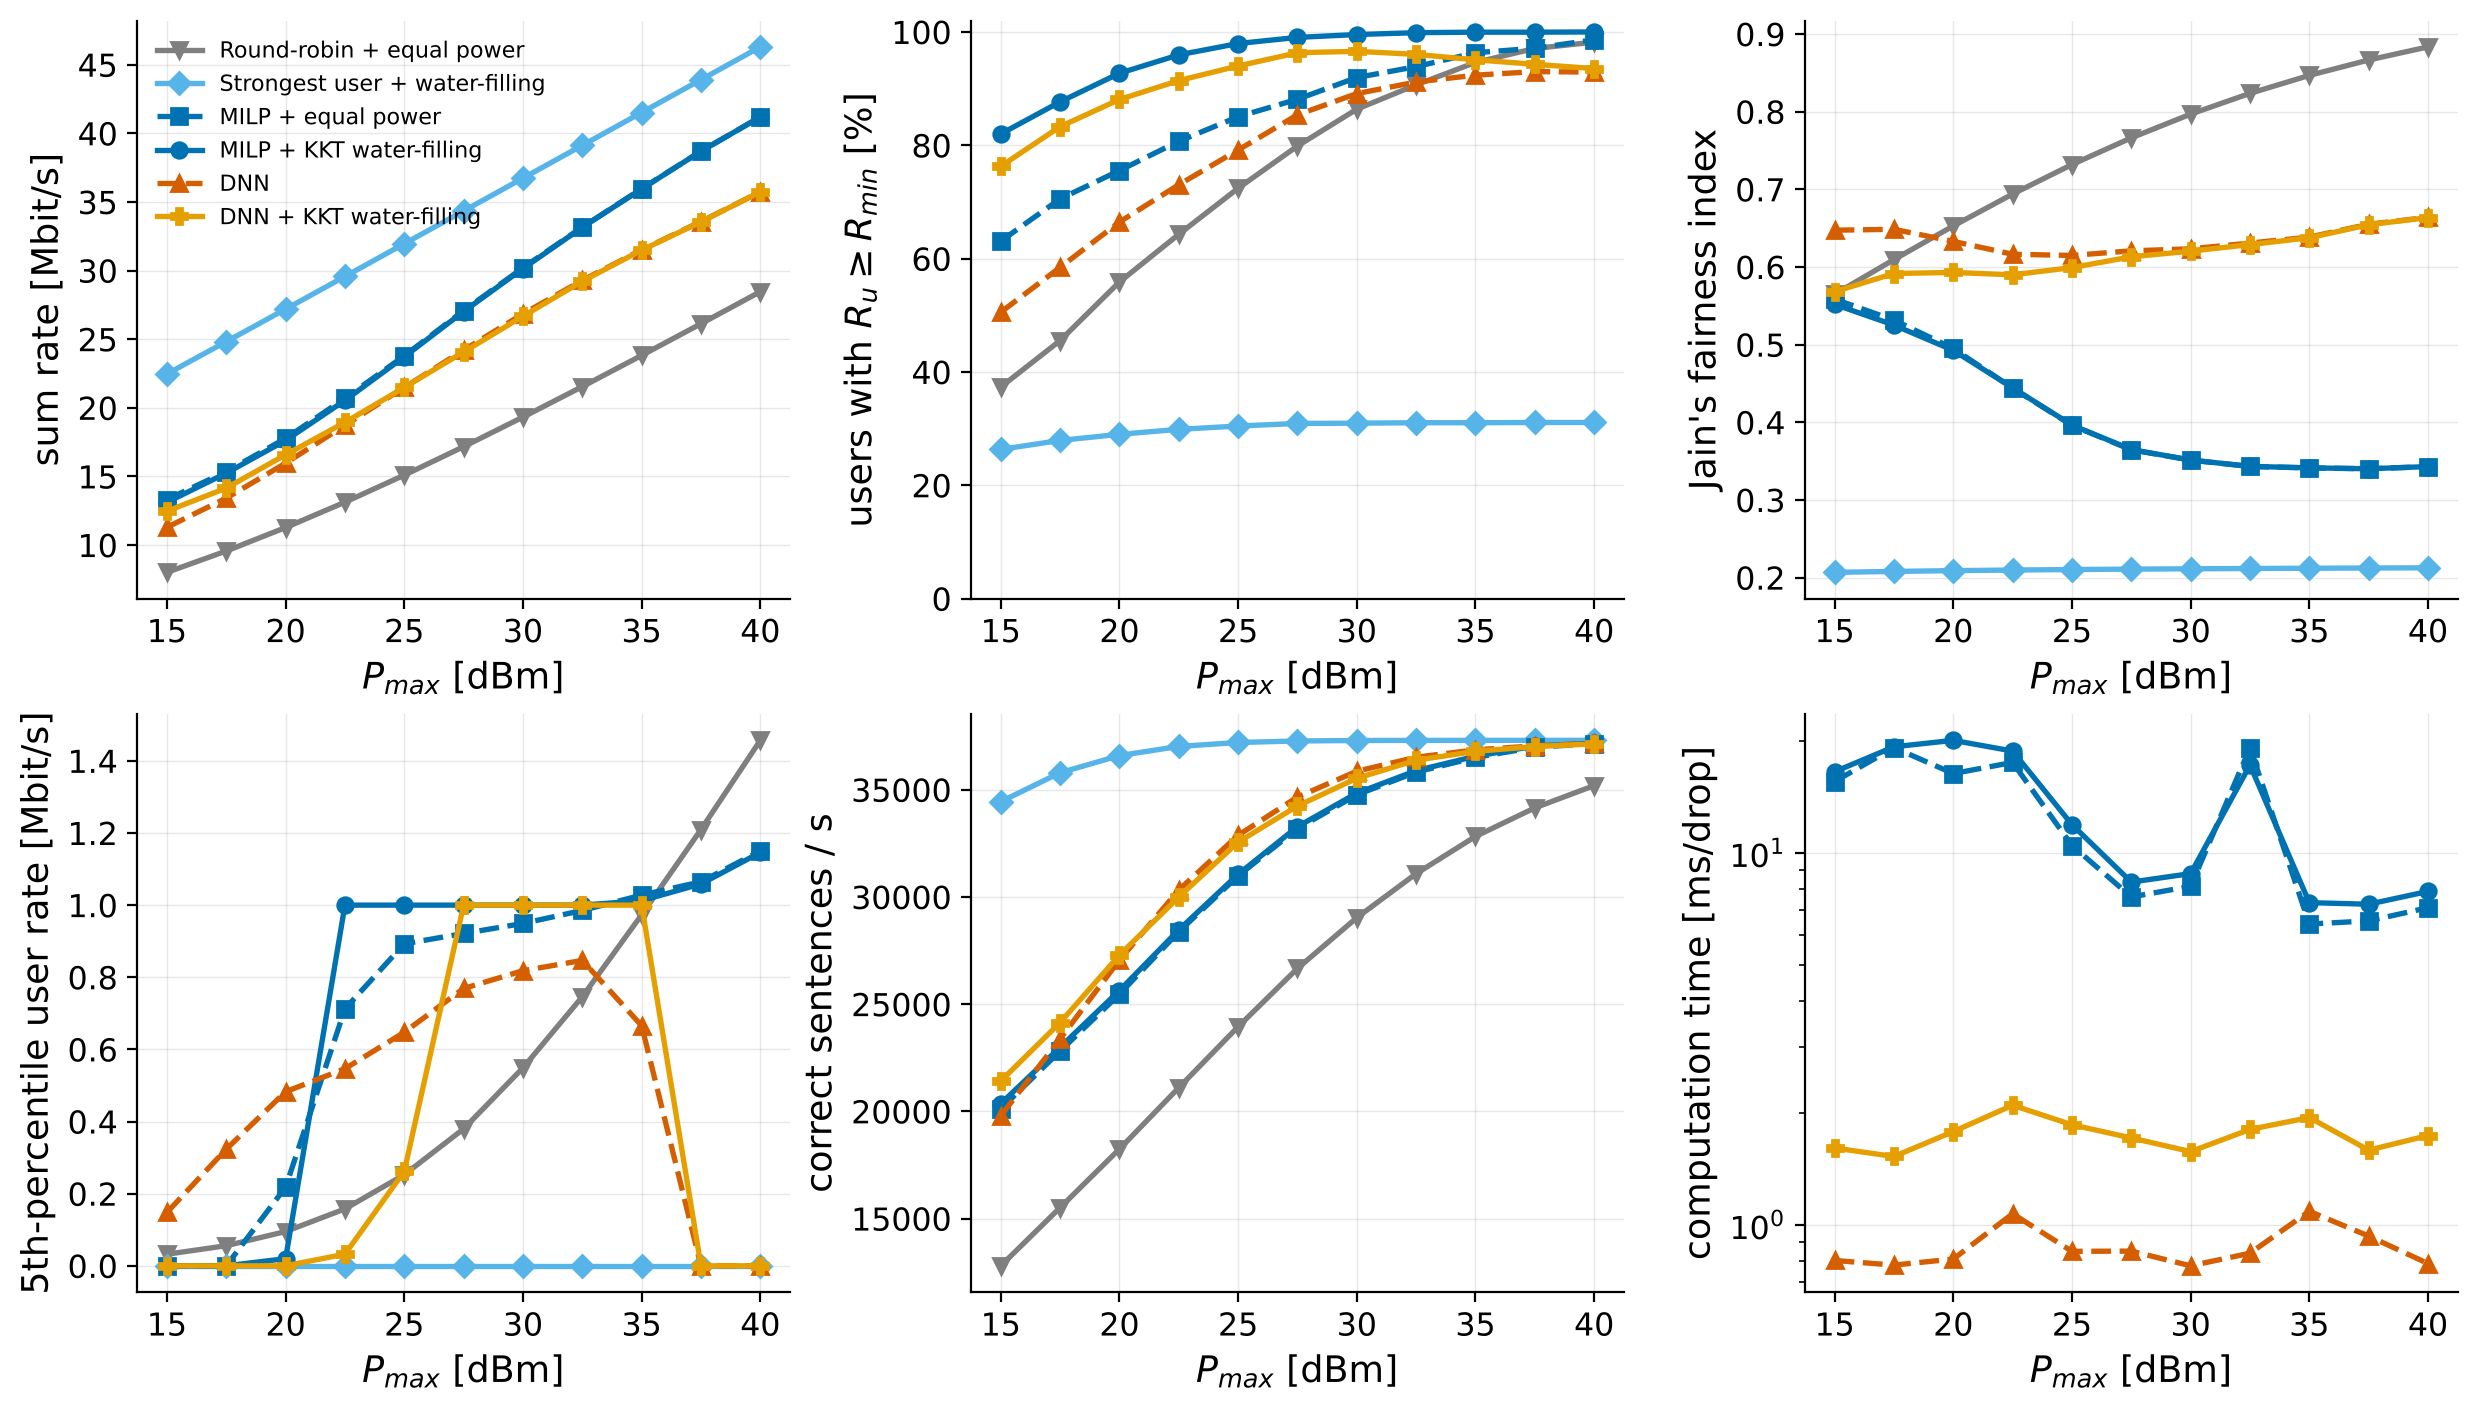

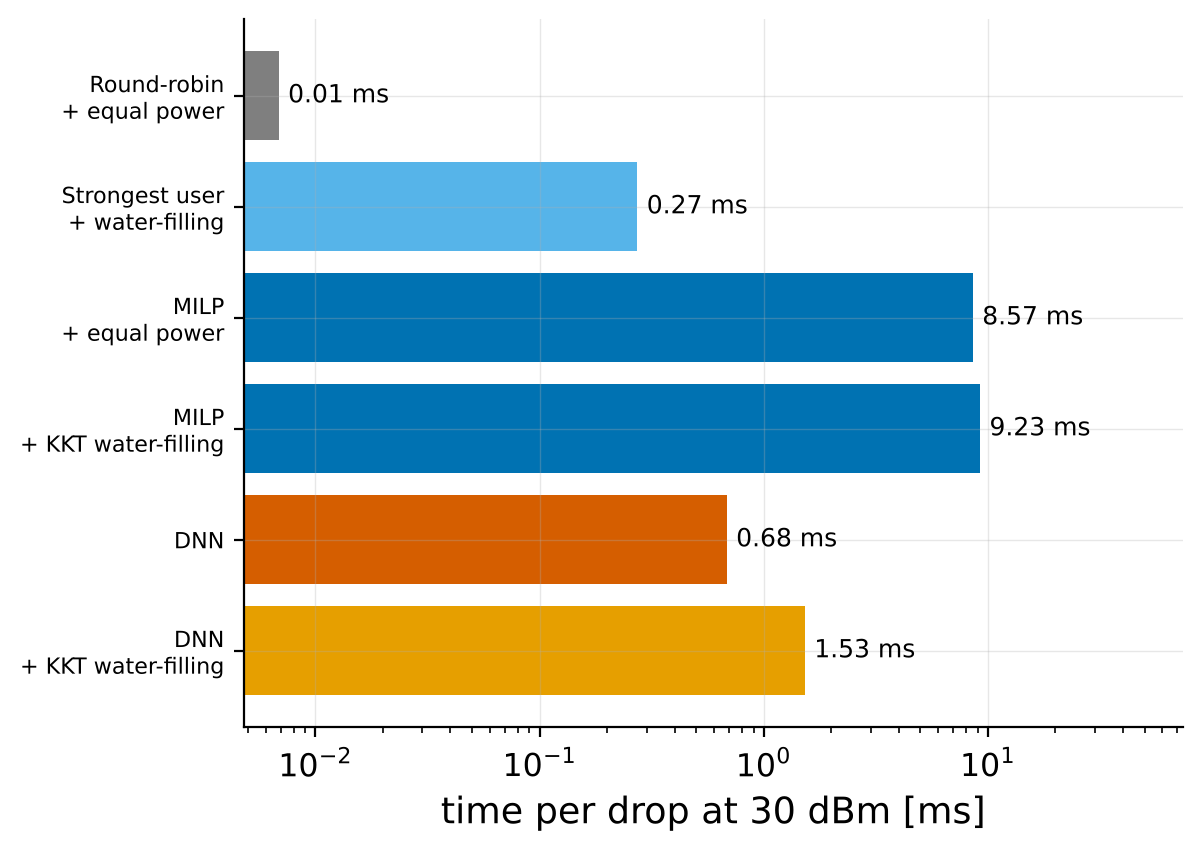

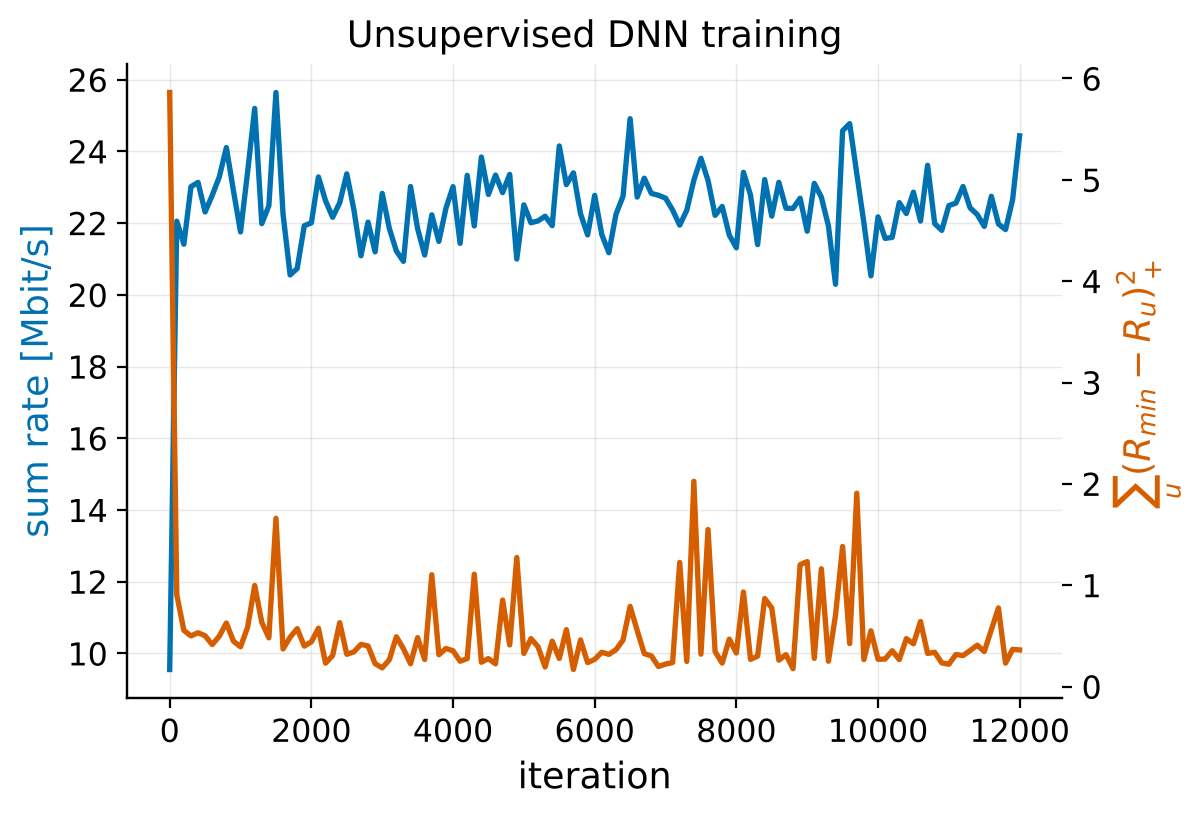

In [28]:
show("fig_ra_main", "fig_ra_time_bar", "fig_ra_training", width=900)

## 6. Export every figure (paper PDFs and slide PNGs)

In [29]:
make_figures.main()
print(sorted(os.listdir(os.path.join(config.FIG_DIR, "paper"))))

[figures] written to /home/claude/ex1/figures
['t1_amc.pdf', 't1_ber_validation.pdf', 't1_coded_curves.pdf', 't1_similarity_lut.pdf', 't1_text_quality.pdf', 't2_ae24_ser.pdf', 't2_ae74_awgn.pdf', 't2_ae74_rayleigh.pdf', 't2_constellation.pdf', 't2_training.pdf', 't3_main.pdf', 't3_time_bar.pdf', 't3_training.pdf']


## 7. Discussion and hooks for Exercise 2

* **Cliff effect (Task 1c).** The convolutional code corrects all errors until the Viterbi decoder leaves its waterfall region (BLER falls from 90&nbsp;% to 1&nbsp;% within 2.5&ndash;3.5&nbsp;dB in AWGN), then errors arrive in bursts; the variable-length Huffman code cannot resynchronise, so one residual bit error corrupts the rest of the sentence. Similarity degrades more gracefully than BLEU or word accuracy.
* **AMC (Task 1d).** Highest rate with BLER &le; 10&nbsp;% &mdash; thresholds 2.3, 4.9, 7.3, 10.9, 14.3 and 15.9&nbsp;dB (AWGN). The AWGN table is used in Task&nbsp;3 because an RB's SNR already contains its (block-constant) Rayleigh fading.
* **Autoencoder (Task 2).** Equals ML on its own codebook, matches or slightly beats Hamming(7,4)-ML in AWGN through a better codebook, and clearly wins in Rayleigh fading (diversity); (2,4) beats 16-QAM by about 0.5&nbsp;dB at moderate SER.
* **L2O (Task 3).** The equivariant DNN reaches 86&ndash;91&nbsp;% of the MILP+KKT sum rate at 6&ndash;13&times; lower latency with a fairer allocation, but without a feasibility guarantee; the KKT hybrid restores most of the QoS.

**Reuse in Exercise 2:** `config.py` (same cell and corpus split), `resource_alloc.generate_drops` (same channel drops), `link.TxFrames/run` (replace source/channel coding by a semantic encoder), `task3_ra.sentences_per_second` (same cross-layer metric) and `data/amc_lut.npz` (BLER and similarity versus SNR, the interface between link and allocator).